# UI3D — Pipeline 3D City Model UI Depok (Google Colab)

Semua langkah (00–11) dalam satu notebook. Jalankan berurutan dari atas.

**Persiapan (sekali):**
1. Upload folder `ui3d/` ke Google Drive, ke `MyDrive/ui3d` (minimal `config.yaml`, `requirements.txt`,
   `notebooks/`, `raw/`). Folder `.venv/` dan `models/` tidak perlu diupload; `interim/`, `output/`, `models/`,
   `figures/` dibuat ulang oleh notebook.
2. Buka `main.ipynb` dari Drive dengan Google Colab.
3. **Runtime → Change runtime type → T4 GPU** (wajib untuk bagian 04 Mask R-CNN).
4. Jalankan sel setup di bawah. Bila folder di Drive bukan `MyDrive/ui3d`, ubah `UI3D_DIR`.

Semua hasil tersimpan di Drive, jadi aman bila sesi Colab terputus. Setelah runtime restart, jalankan ulang
sel setup, lalu sel import bagian yang ingin dilanjutkan.

Bagian:
- 00_setup
- 01_aoi
- 02_terrain
- 03_imagery_footprint
- 04_maskrcnn
- 05_footprint_eval
- 06_height_gdb
- 07_procedural
- 08_webgis
- 09_flood
- 10_indoor
- 11_animation

In [ ]:
# Setup Colab: mount Drive, pindah ke folder proyek, pasang library, siapkan render PyVista tanpa layar.
import os
import sys

from google.colab import drive

UI3D_DIR = "/content/drive/MyDrive/ui3d"  # ubah bila folder ui3d disimpan di tempat lain

drive.mount("/content/drive")
assert os.path.exists(f"{UI3D_DIR}/config.yaml"), f"config.yaml tidak ada di {UI3D_DIR}; cek lokasi upload"
os.chdir(UI3D_DIR)
sys.path.insert(0, f"{UI3D_DIR}/notebooks")  # helper ui3d_common, download

%pip install -q -r requirements.txt
%pip install -q --no-deps rvt-py
!apt-get -qq install -y xvfb > /dev/null

import pyvista as pv

pv.start_xvfb()  # PyVista (bagian 07, 09, 11) butuh display virtual di Colab

# 00 — Setup lingkungan

Langkah 0 PRD di Google Colab. Sel setup di atas sudah mount Drive dan memasang library dari `requirements.txt`.

1. Cek library, folder kerja, file data mentah, GPU, dan grid geoid EGM2008.
2. Parameter global ada di `config.yaml` (CRS, path, `GFl`, `Fl`, konstanta +1,0 m, level banjir).
   Edit langsung di Drive, lalu jalankan ulang sel import bagian yang terkait.

In [1]:
import importlib
import sys

from ui3d_common import CFG, ROOT, raw

print("Python", sys.version.split()[0])
print("Root proyek:", ROOT)

Python 3.10.12
Root proyek: /home/luwes-system/Desktop/bahan ajar 2026/ui3d


## Cek library

In [2]:
LIBS = ["numpy", "pandas", "geopandas", "shapely", "pyproj", "rasterio", "scipy", "skimage", "yaml",
        "matplotlib", "plotly", "trimesh", "mapbox_earcut", "pydeck", "PIL", "torch", "torchvision"]
for name in LIBS:
    try:
        m = importlib.import_module(name)
        print(f"OK   {name:15s} {getattr(m, '__version__', '')}")
    except ImportError as e:
        print(f"MISS {name:15s} {e}")

OK   numpy           2.2.6
OK   pandas          2.3.3
OK   geopandas       1.1.4
OK   shapely         2.1.2
OK   pyproj          3.7.1
OK   rasterio        1.4.4
OK   scipy           1.15.3
OK   skimage         0.25.2
OK   yaml            6.0.3
OK   matplotlib      3.10.9
OK   plotly          7.1.0


OK   trimesh         5.1.1
OK   mapbox_earcut   2.1.0
OK   pydeck          0.9.3
OK   PIL             12.3.0


OK   torch           2.14.1+cu130


OK   torchvision     0.29.1+cu130


## Folder kerja

In [3]:
for key in ("raw", "interim", "output", "models", "figures"):
    d = ROOT / CFG["paths"][key]
    d.mkdir(parents=True, exist_ok=True)
    print(d)

/home/luwes-system/Desktop/bahan ajar 2026/ui3d/raw
/home/luwes-system/Desktop/bahan ajar 2026/ui3d/interim
/home/luwes-system/Desktop/bahan ajar 2026/ui3d/output
/home/luwes-system/Desktop/bahan ajar 2026/ui3d/models
/home/luwes-system/Desktop/bahan ajar 2026/ui3d/figures


## File data mentah

Semua sudah diunduh ke `raw/` (lihat `raw/README.md`). Yang hilang bisa diunduh ulang di sel berikutnya,
kecuali DEMNAS dan Open Buildings 2.5D (butuh akun, unduh manual).

In [4]:
missing = []
for key, rel in CFG["raw"].items():
    ok = raw(key).exists()
    print(("OK  " if ok else "MISS"), key, rel)
    if not ok:
        missing.append(key)
missing

OK   aoi raw/aoi_ui.gpkg
OK   osm raw/osm_ui.gpkg
OK   osm_xml raw/osm_ui_bbox.osm
OK   demnas raw/DEMNAS_1209-42_v1.0.tif
OK   copdem raw/copdem_glo30_ui.tif
OK   icesat2 raw/icesat2_atl08_ui.gpkg
OK   imagery raw/ui_rgb_esri_z19.tif
OK   gob_v3 raw/gob_v3_ui_bbox.gpkg
OK   gob_25d raw/OpenBuildings25D_UI_Depok_2023.tif


[]

In [5]:
# Unduh ulang hanya file yang hilang. Set True untuk menjalankan.
REDOWNLOAD = False

if REDOWNLOAD and missing:
    import geopandas as gpd

    import download as dl

    bbox = tuple(CFG["aoi"]["bbox_fallback"])
    pad = CFG["aoi"]["terrain_buffer_m"] / 111_000  # derajat kira-kira
    bbox_terrain = (bbox[0] - pad, bbox[1] - pad, bbox[2] + pad, bbox[3] + pad)
    if "aoi" in missing:
        dl.aoi(CFG["aoi"]["query"], bbox, raw("aoi"))
    if "osm" in missing or "osm_xml" in missing:
        poly = gpd.read_file(raw("aoi"), layer="aoi_buf50").geometry.iloc[0]
        dl.osm(poly.bounds, raw("osm_xml"), raw("osm"), poly)
    if "copdem" in missing:
        dl.copdem(bbox_terrain, raw("copdem"))
    if "imagery" in missing:
        dl.esri(bbox, CFG["imagery"]["zoom"], raw("imagery"))
    if "imagery_context" in missing:
        dl.esri(bbox_terrain, CFG["imagery"]["context_zoom"], raw("imagery_context"))
    if "gob_v3" in missing:
        dl.gob_v3(bbox, raw("gob_v3"))
    if "icesat2" in missing:
        dl.icesat2(bbox_terrain, raw("icesat2"))
    for key in ("demnas", "gob_25d"):
        if key in missing:
            print(f"{key}: unduh manual (butuh akun), simpan ke {CFG['raw'][key]}")

## GPU (untuk Langkah 4)

Training Mask R-CNN di CPU bisa makan berjam-jam per epoch. Pastikan runtime Colab memakai GPU (**Runtime → Change runtime type → T4 GPU**).
Bila `CUDA: False`, ganti runtime lalu jalankan ulang dari sel setup.

In [6]:
import torch

print("CUDA:", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

CUDA: True NVIDIA GeForce RTX 3050


## Grid geoid EGM2008

Konversi tinggi ICESat-2 (ellipsoid) ke EGM2008 butuh grid PROJ `us_nga_egm08_25.tif`.
Sel ini mengaktifkan jaringan PROJ agar grid diunduh otomatis saat dipakai, lalu menguji transformasinya.

In [7]:
import pyproj
from pyproj import Transformer

pyproj.network.set_network_enabled(True)
t = Transformer.from_crs(CFG["crs"]["icesat2_src"], CFG["crs"]["vertical"], always_xy=True)
_, _, h = t.transform(106.826, -6.36, 100.0)
print(f"h ellipsoid 100 m -> EGM2008 {h:.2f} m (undulasi ~{100 - h:.1f} m; harus jauh dari 0)")

h ellipsoid 100 m -> EGM2008 82.04 m (undulasi ~18.0 m; harus jauh dari 0)


# 01 — Area studi (AOI)

- **Input**: poligon kampus UI dari OSM (`raw/aoi_ui.gpkg`, hasil `osmnx.geocode_to_gdf`); bila belum ada,
  geocode ulang dengan fallback bbox manual.
- **Proses**: proyeksi ke EPSG:32748, buffer 50 m, dan buffer 3 km untuk evaluasi terrain.
- **Output**: `interim/aoi.gpkg` (layer `aoi`, `aoi_buf50`, `aoi_terrain`), luas AOI, peta lokasi (setara Fig. 1–2).

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import rasterio
from rasterio.plot import show
from shapely.geometry import box

from ui3d_common import CFG, CRS, hillshade, interim, raw, savefig

In [2]:
if raw("aoi").exists():
    aoi_ll = gpd.read_file(raw("aoi"), layer="aoi")
else:
    import osmnx as ox
    try:
        aoi_ll = ox.geocode_to_gdf(CFG["aoi"]["query"])[["geometry"]]
    except Exception as e:  # noqa: BLE001 - fallback sesuai PRD
        print("geocode gagal, pakai bbox manual:", e)
        aoi_ll = gpd.GeoDataFrame(geometry=[box(*CFG["aoi"]["bbox_fallback"])], crs=4326)

aoi = aoi_ll[["geometry"]].to_crs(CRS)
aoi["name"] = "Universitas Indonesia"
aoi_buf = gpd.GeoDataFrame({"name": ["AOI + 50 m"]}, geometry=aoi.buffer(CFG["aoi"]["buffer_m"]), crs=CRS)
aoi_terrain = gpd.GeoDataFrame({"name": ["AOI + 3 km"]}, geometry=aoi.buffer(CFG["aoi"]["terrain_buffer_m"]), crs=CRS)

dst = interim("aoi.gpkg")
aoi.to_file(dst, layer="aoi")
aoi_buf.to_file(dst, layer="aoi_buf50")
aoi_terrain.to_file(dst, layer="aoi_terrain")

area = aoi.area.iloc[0]
print(f"Luas AOI: {area / 1e4:,.1f} ha = {area / 1e6:.2f} km²")
print(f"Luas AOI + 50 m: {aoi_buf.area.iloc[0] / 1e6:.2f} km²; AOI + 3 km: {aoi_terrain.area.iloc[0] / 1e6:.2f} km²")

Luas AOI: 276.6 ha = 2.77 km²
Luas AOI + 50 m: 3.21 km²; AOI + 3 km: 54.82 km²


## Peta lokasi (setara Fig. 1–2)

Kiri: AOI dalam konteks buffer terrain 3 km di atas DEMNAS (warna elevasi di atas hillshade, z×3; rumus hillshade\ndi bagian 02). Kanan: AOI di atas citra Esri.

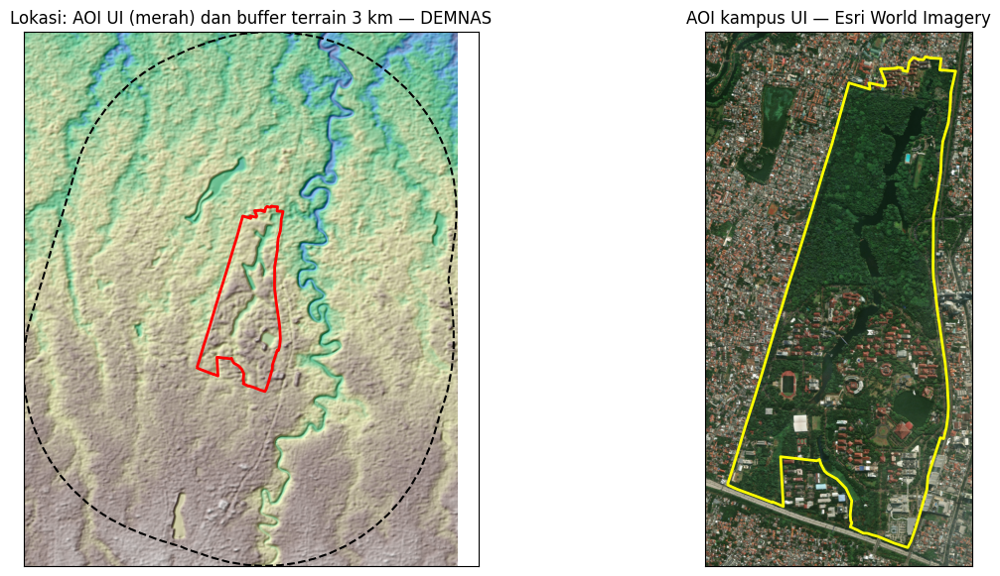

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 7))

with rasterio.open(raw("demnas")) as src:
    b = aoi_terrain.to_crs(src.crs).total_bounds
    win = rasterio.windows.from_bounds(*b, src.transform)
    dem = src.read(1, window=win).astype(float)
    wtr = src.window_transform(win)
    # DEMNAS dalam derajat: ukuran piksel ke meter (~111,3 km/derajat di ekuator) untuk hillshade
    hs = hillshade(dem, src.res[0] * 111_320, z_factor=3)
    show(hs, transform=wtr, ax=ax[0], cmap="gray", vmin=0, vmax=1)
    show(dem, transform=wtr, ax=ax[0], cmap="terrain", alpha=0.45)
aoi_terrain.to_crs(4326).boundary.plot(ax=ax[0], color="k", ls="--")
aoi.to_crs(4326).boundary.plot(ax=ax[0], color="red", lw=2)
ax[0].set_title("Lokasi: AOI UI (merah) dan buffer terrain 3 km — DEMNAS")

with rasterio.open(raw("imagery")) as src:
    f = max(1, src.width // 1500)
    img = src.read(out_shape=(3, src.height // f, src.width // f))
    tr = src.transform * src.transform.scale(src.width / img.shape[2], src.height / img.shape[1])
    show(img, transform=tr, ax=ax[1])
    aoi.to_crs(src.crs).boundary.plot(ax=ax[1], color="yellow", lw=2)
ax[1].set_title("AOI kampus UI — Esri World Imagery")
for a in ax:
    a.set_xticks([]); a.set_yticks([])
savefig(fig, "fig01_02_lokasi_aoi.png")
plt.show()

# 02 — Terrain dan evaluasinya

Padanan evaluasi DEM vs grid levelling di paper (Fig. 4, 14, 15):

1. DEMNAS → clip AOI + 3 km, reproject + resample ke grid 8 m UTM 48S.
2. Copernicus GLO-30 → grid yang sama.
3. ICESat-2 ATL08 (`terrain/h_te_best_fit`, segmen 100 m) sebagai referensi; buang fill dan uncertainty tinggi.
   Data diambil lewat SlideRule (`raw/icesat2_atl08_ui.gpkg`), bukan `earthaccess`, agar tanpa akun Earthdata.
4. Konversi tinggi ICESat-2 ellipsoid WGS84 → EGM2008.
5. `ΔZ = Z_DEM − Z_ICESat2`, statistik setara paper, histogram kelas 0,2 m, scatter, permukaan 3D.
6. Hillshade DEMNAS vs Copernicus untuk membandingkan relief secara visual.

**Output**: `output/dem_ui_8m.tif`, `interim/copdem_ui_8m.tif`, `interim/terrain_points.gpkg`,
`output/terrain_eval.csv`, 4 figure.

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import pyproj
import rasterio
from pyproj import Transformer
from rasterio.transform import from_origin
from rasterio.warp import Resampling, reproject

from ui3d_common import CFG, CRS, aoi, fig_path, hillshade, interim, out, raw, savefig

T = CFG["terrain"]
RES = T["grid_m"]
aoi_t = aoi("aoi_terrain")

## 1–2. DEMNAS dan Copernicus ke grid 8 m yang sama

In [2]:
x0, y0, x1, y1 = aoi_t.total_bounds
x0, y0 = np.floor(x0 / RES) * RES, np.floor(y0 / RES) * RES
W, H = int(np.ceil((x1 - x0) / RES)), int(np.ceil((y1 - y0) / RES))
GRID_TR = from_origin(x0, y0 + H * RES, RES, RES)


def to_grid(src_path, dst_path):
    with rasterio.open(src_path) as s:
        dst = np.full((H, W), np.nan, "float32")
        reproject(rasterio.band(s, 1), dst, src_crs=s.crs or "EPSG:4326", src_nodata=s.nodata,
                  dst_transform=GRID_TR, dst_crs=CRS, dst_nodata=np.nan, resampling=Resampling.bilinear)
    prof = dict(driver="GTiff", height=H, width=W, count=1, dtype="float32", crs=CRS, transform=GRID_TR,
                nodata=np.nan, compress="deflate")
    with rasterio.open(dst_path, "w", **prof) as d:
        d.write(dst, 1)
    return dst


dems = {"DEMNAS": to_grid(raw("demnas"), out("dem_ui_8m.tif")),
        "Copernicus GLO-30": to_grid(raw("copdem"), interim("copdem_ui_8m.tif"))}
for k, v in dems.items():
    print(f"{k}: {v.shape}, {np.nanmin(v):.1f}–{np.nanmax(v):.1f} m, NaN {np.isnan(v).mean():.1%}")

DEMNAS: (1150, 938), 27.3–100.0 m, NaN 0.0%
Copernicus GLO-30: (1150, 938), 29.8–108.8 m, NaN 0.0%


## 3. ICESat-2 ATL08: filter fill dan uncertainty

In [3]:
pts = gpd.read_file(raw("icesat2"), layer="atl08_100m")
print("CRS file:", pts.crs, "| segmen:", len(pts))
FILL = 1e30
h = pts["terrain/h_te_best_fit"].astype(float)
u = pts["terrain/h_te_uncertainty"].astype(float)
ok = np.isfinite(h) & (h < FILL) & np.isfinite(u) & (u < FILL) & (u <= T["max_uncertainty_m"])
pts = pts[ok].copy()
print(f"Lolos filter: {len(pts)} segmen (uncertainty <= {T['max_uncertainty_m']} m)")

CRS file: EPSG:7912 | segmen: 2254
Lolos filter: 1465 segmen (uncertainty <= 5.0 m)


## 4. Ellipsoid WGS84 → EGM2008

Butuh grid geoid PROJ (lihat bagian 00). Bila grid tidak tersedia, PROJ diam-diam tidak mengubah tinggi,
jadi hasilnya dicek: selisih ellipsoid–geoid di Depok harus belasan meter, bukan 0.

In [4]:
pyproj.network.set_network_enabled(True)
t = Transformer.from_crs(CFG["crs"]["icesat2_src"], CFG["crs"]["vertical"], always_xy=True)
lon, lat = pts.geometry.x.values, pts.geometry.y.values
h_ell = pts["terrain/h_te_best_fit"].astype(float).values
_, _, h_egm = t.transform(lon, lat, h_ell)
N_geoid = h_ell - h_egm
# inf = grid gagal diunduh; 0 = PROJ diam-diam memakai transformasi "ballpark" tanpa grid
assert np.isfinite(N_geoid).all() and np.abs(N_geoid).min() > 1, \
    "Grid geoid EGM2008 tidak terpakai; jalankan sel geoid di bagian 00"
print(f"Undulasi geoid: {N_geoid.mean():.2f} ± {N_geoid.std():.2f} m")
pts["h_ellps"], pts["h_egm08"] = h_ell, h_egm
pts = pts.to_crs(CRS)

Undulasi geoid: 17.97 ± 0.07 m


## 5. Sampling DEM di titik ICESat-2 dan ΔZ

In [5]:
rows, cols = rasterio.transform.rowcol(GRID_TR, pts.geometry.x.values, pts.geometry.y.values)
rows, cols = np.asarray(rows), np.asarray(cols)
inside = (rows >= 0) & (rows < H) & (cols >= 0) & (cols < W)
pts = pts[inside].copy()
rows, cols = rows[inside], cols[inside]
for k, v in dems.items():
    pts[f"z_{k}"] = v[rows, cols]
    pts[f"dz_{k}"] = pts[f"z_{k}"] - pts["h_egm08"]
pts = pts.dropna(subset=[f"dz_{k}" for k in dems])

# Subset "tanah terbuka": jauh dari gedung OSM dan kanopi rendah (DEM radar = DSM).
# Catatan: footprint OSM di raw/ hanya mencakup AOI kampus, jadi di luar AOI filter ini hanya memakai kanopi.
bld = gpd.read_file(raw("osm"), layer="buildings").to_crs(CRS)
bld = bld[bld.geom_type.isin(["Polygon", "MultiPolygon"])]
dist = pts.geometry.apply(lambda p: bld.distance(p).min()) if len(bld) else np.inf
canopy = pd.to_numeric(pts.get("h_canopy"), errors="coerce")
canopy = canopy.where(canopy < FILL)  # index sama dengan pts
pts["open_ground"] = (dist > T["open_ground_dist_m"]) & (canopy.isna() | (canopy < T["open_ground_max_canopy_m"]))
print(f"Titik dipakai: {len(pts)}; tanah terbuka: {pts.open_ground.sum()}")
pts.drop(columns=[c for c in pts.columns if pts[c].dtype == object and c != "geometry"]).to_file(
    interim("terrain_points.gpkg"), layer="terrain_points")

Titik dipakai: 1249; tanah terbuka: 15


## 6. Statistik setara paper

In [6]:
def stats(dz):
    a = np.abs(dz)
    med = np.median(dz)
    s = dict(n=len(dz), min=dz.min(), max=dz.max(), mean=dz.mean(), median=med, std=dz.std(), max_abs=a.max(),
             rmse=np.sqrt(np.mean(dz ** 2)), nmad=1.4826 * np.median(np.abs(dz - med)), le90=np.percentile(a, 90))
    s.update({f"pct_abs_lt_{t}m": (a < t).mean() * 100 for t in T["thresholds_m"]})
    return s


rows_ = []
for k in dems:
    subsets = (("semua", np.ones(len(pts), bool)),
               (f"kanopi_lt_{T['low_canopy_m']:g}m", (canopy.isna() | (canopy < T["low_canopy_m"])).values),
               ("tanah_terbuka", pts.open_ground.values))
    for subset, m in subsets:
        if m.sum():
            rows_.append(dict(dem=k, subset=subset, **stats(pts.loc[m, f"dz_{k}"].values)))
ev = pd.DataFrame(rows_).round(3)
ev.to_csv(out("terrain_eval.csv"), index=False)
# NMAD = 1,4826 × median|ΔZ − median|: sebaran galat yang tahan pencilan (kanopi, atap, awan).
print(f"Titik dengan kanopi ICESat-2 < {T['low_canopy_m']:g} m: {int((canopy < T['low_canopy_m']).sum())}")
print("Paper (Mansoura): selisih maks. 0,85 m; 90% sel < 0,85 m")
ev

Titik dengan kanopi ICESat-2 < 5 m: 57
Paper (Mansoura): selisih maks. 0,85 m; 90% sel < 0,85 m


,dem,subset,n,min,max,mean,median,std,max_abs,rmse,nmad,le90,pct_abs_lt_0.2m,pct_abs_lt_0.4m,pct_abs_lt_0.65m,pct_abs_lt_0.85m
0,DEMNAS,semua,1249,-30.321,68.392,-0.611,-0.897,7.612,68.392,7.637,3.109,8.992,4.564,8.647,14.091,20.496
1,DEMNAS,kanopi_lt_5m,57,-16.827,68.054,-2.433,-5.572,17.723,68.054,17.889,5.485,16.716,0.000,0.000,0.000,3.509
2,DEMNAS,tanah_terbuka,15,-16.827,49.312,-6.806,-11.485,16.437,49.312,17.791,7.355,16.805,0.000,0.000,0.000,0.000
3,Copernicus GLO-30,semua,1249,-26.130,72.155,2.452,2.110,7.342,72.155,7.741,2.379,8.104,2.722,5.925,9.528,13.211
4,Copernicus GLO-30,kanopi_lt_5m,57,-10.582,72.022,2.631,-0.639,16.690,72.022,16.896,3.170,10.386,7.018,10.526,22.807,28.070
5,Copernicus GLO-30,tanah_terbuka,15,-2.778,50.725,3.971,-0.626,12.790,50.725,13.393,0.306,7.243,0.000,0.000,40.000,53.333


## Histogram |ΔZ| kelas 0,2 m (setara Fig. 15) dan scatter ΔZ (setara Fig. 14)

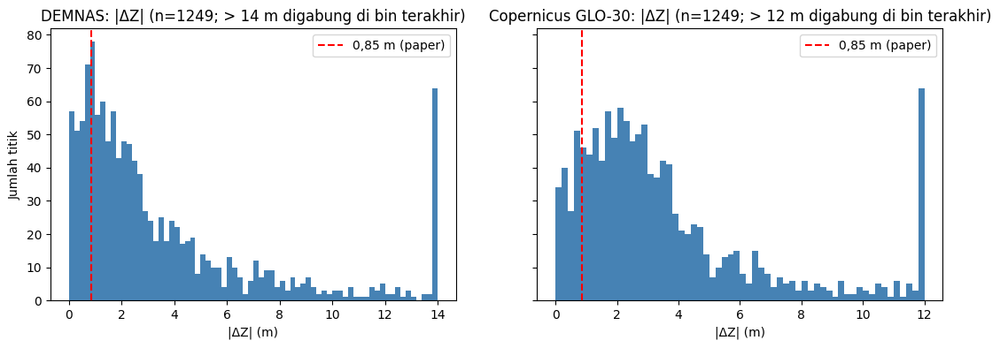

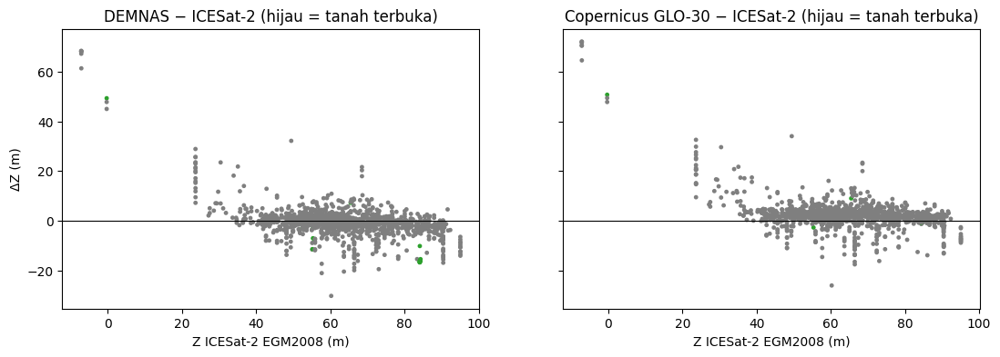

In [7]:
fig, ax = plt.subplots(1, len(dems), figsize=(13, 4), sharey=True)
for a, k in zip(ax, dems):
    v = np.abs(pts[f"dz_{k}"])
    top = max(1.0, np.ceil(np.percentile(v, 95)))
    a.hist(np.clip(v, 0, top), bins=np.arange(0, top + 0.2, 0.2), color="steelblue")
    a.axvline(0.85, color="r", ls="--", label="0,85 m (paper)")
    a.set(title=f"{k}: |ΔZ| (n={len(v)}; > {top:.0f} m digabung di bin terakhir)", xlabel="|ΔZ| (m)")
    a.legend()
ax[0].set_ylabel("Jumlah titik")
savefig(fig, "fig15_hist_dz.png")
plt.show()

fig, ax = plt.subplots(1, len(dems), figsize=(13, 4), sharey=True)
for a, k in zip(ax, dems):
    c = np.where(pts.open_ground, "tab:green", "tab:gray")
    a.scatter(pts["h_egm08"], pts[f"dz_{k}"], s=6, c=c)
    a.axhline(0, color="k", lw=0.8)
    a.set(title=f"{k} − ICESat-2 (hijau = tanah terbuka)", xlabel="Z ICESat-2 EGM2008 (m)")
ax[0].set_ylabel("ΔZ (m)")
savefig(fig, "fig14_scatter_dz.png")
plt.show()

## 7. Permukaan 3D terrain AOI (setara Fig. 4)

In [8]:
b = aoi().total_bounds
r0, c0 = rasterio.transform.rowcol(GRID_TR, b[0], b[3])
r1, c1 = rasterio.transform.rowcol(GRID_TR, b[2], b[1])
z = dems["DEMNAS"][r0:r1 + 1, c0:c1 + 1]
xs = GRID_TR.c + (np.arange(c0, c1 + 1) + 0.5) * RES
ys = GRID_TR.f - (np.arange(r0, r1 + 1) + 0.5) * RES
f3 = go.Figure(go.Surface(x=xs, y=ys, z=z, colorscale="Earth"))
f3.update_layout(title="Terrain DEMNAS 8 m — kampus UI", scene=dict(aspectmode="manual", aspectratio=dict(x=1, y=2, z=0.3)))
f3.write_html(fig_path("fig04_terrain_surface.html"))
f3.show()

## 8. Hillshade DEMNAS vs Copernicus

Hillshade = kecerahan permukaan bila disinari matahari dari arah `azimuth` (315° = barat laut) dan
ketinggian `altitude` (45°). Rumusnya metode Horn, sama dengan `gdaldem hillshade`:

1. Gradien `dz/dx`, `dz/dy` dari jendela 3×3 (bobot 1-2-1).
2. `slope = arctan(√(dz/dx² + dz/dy²))`, `aspect = arctan2(dz/dy, −dz/dx)`.
3. `hs = cos(zenith)·cos(slope) + sin(zenith)·sin(slope)·cos(azimuth − aspect)`.

Relief Depok landai, jadi `z_factor = 3` (eksagerasi vertikal) agar lembah sungai dan teras terlihat.
Hillshade memperlihatkan hal yang tidak tampak di RMSE: DEMNAS lebih tajam (alur sungai di timur kampus
jelas) tetapi bertekstur berbintik karena kanopi dan atap ikut terekam. Copernicus lebih halus karena
resolusi aslinya 30 m, tetapi gedung kampus tetap muncul sebagai gundukan (keduanya DSM, bukan DTM).

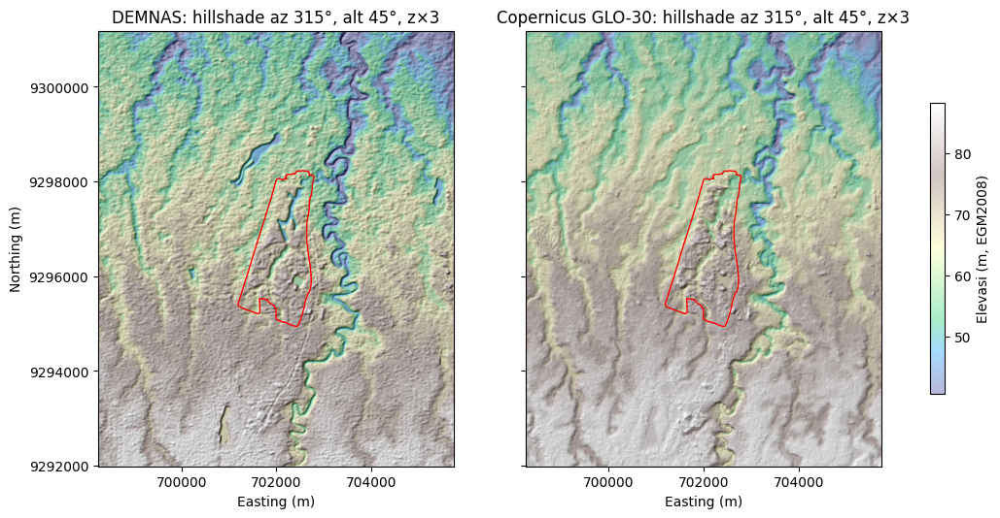

In [9]:
Z_FACTOR = 3
hs = {k: hillshade(v, RES, z_factor=Z_FACTOR) for k, v in dems.items()}

ext = (GRID_TR.c, GRID_TR.c + W * RES, GRID_TR.f - H * RES, GRID_TR.f)
zmin, zmax = np.nanpercentile(dems["DEMNAS"], [2, 98])
fig, ax = plt.subplots(1, len(dems), figsize=(13, 6.5), sharey=True)
for a, k in zip(ax, dems):
    a.imshow(hs[k], cmap="gray", extent=ext, vmin=0, vmax=1)
    im = a.imshow(dems[k], cmap="terrain", extent=ext, vmin=zmin, vmax=zmax, alpha=0.35)
    aoi().boundary.plot(ax=a, color="red", lw=1)
    a.set(title=f"{k}: hillshade az 315°, alt 45°, z×{Z_FACTOR}", xlabel="Easting (m)")
    a.ticklabel_format(style="plain", useOffset=False)
    a.xaxis.set_major_locator(plt.MaxNLocator(4))
ax[0].set_ylabel("Northing (m)")
fig.colorbar(im, ax=ax, shrink=0.6, label="Elevasi (m, EGM2008)")
savefig(fig, "fig04b_hillshade.png")
plt.show()

# 03 — Citra dan footprint referensi

1. Citra Esri World Imagery zoom 19 (`raw/ui_rgb_esri_z19.tif`, EPSG:3857) → reproject ke UTM 0,3 m,
   clip AOI + 50 m → `interim/ui_rgb.tif` (8-bit, 3 band). Citra hanya untuk pendidikan; jangan didistribusikan ulang.
2. Layer OSM: gedung, jalan, air, vegetasi.
3. Bersihkan geometri: `make_valid`, explode multipolygon, buang < 10 m².
4. Google Open Buildings v3, confidence ≥ 0,75.
5. Verifikasi visual 25 gedung OSM di atas citra.

**Output**: `output/ref_buildings.gpkg`, `output/gob_buildings.gpkg`, `interim/osm_layers.gpkg`
(roads, water, vegetation), peta tematik (setara Fig. 5–6).

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from matplotlib.patches import Patch
from rasterio.plot import show
from rasterio.warp import Resampling, reproject

from ui3d_common import CATEGORY_COLORS, CFG, CRS, aoi, categorize, interim, out, raw, savefig

F = CFG["footprint"]
aoi_buf = aoi("aoi_buf50")
poly = aoi_buf.geometry.iloc[0]

## 1. Citra ke UTM 0,3 m

In [2]:
img_path = interim("ui_rgb.tif")
res = CFG["imagery"]["res_m"]
with rasterio.open(raw("imagery")) as src:
    # grid UTM yang dipotong ke AOI + 50 m
    x0, y0, x1, y1 = aoi_buf.total_bounds
    x0, y1 = np.floor(x0 / res) * res, np.ceil(y1 / res) * res
    w, h = int(np.ceil((x1 - x0) / res)), int(np.ceil((y1 - y0) / res))
    tr = rasterio.transform.from_origin(x0, y1, res, res)
    prof = dict(driver="GTiff", height=h, width=w, count=3, dtype="uint8", crs=CRS, transform=tr,
                tiled=True, blockxsize=512, blockysize=512, compress="deflate", nodata=0)
    with rasterio.open(img_path, "w", **prof) as dst:
        for i in (1, 2, 3):
            reproject(rasterio.band(src, i), rasterio.band(dst, i), dst_transform=tr, dst_crs=CRS,
                      resampling=Resampling.bilinear)
print(f"{img_path.name}: {w} x {h} px @ {res} m")

ui_rgb.tif: 5328 x 10965 px @ 0.3 m


## 2–3. Layer OSM dan pembersihan geometri

File OSM mentah menyimpan nilai kosong sebagai teks `"nan"`; diubah kembali ke `None`.

In [3]:
def load_osm(layer):
    g = gpd.read_file(raw("osm"), layer=layer).replace({"nan": None, "None": None}).to_crs(CRS)
    g["geometry"] = g.geometry.make_valid()
    return g.explode(index_parts=False).reset_index(drop=True)


def polygons(g):
    g = g[g.geom_type == "Polygon"]
    return g[g.area >= F["min_area_m2"]].reset_index(drop=True)


buildings = polygons(load_osm("buildings"))
buildings = buildings[buildings.intersects(poly)].reset_index(drop=True)
buildings["category"] = buildings.apply(categorize, axis=1)
buildings["footprint_source"] = "OSM"
buildings["area_m2"] = buildings.area.round(1)

roads = load_osm("roads")
roads = roads[roads.geom_type == "LineString"].reset_index(drop=True)

water_raw = load_osm("water")
water = pd.concat([polygons(water_raw),
                   water_raw[water_raw.geom_type == "LineString"].assign(
                       geometry=lambda d: d.buffer(F["waterway_width_m"] / 2))], ignore_index=True)
water = gpd.GeoDataFrame(water, geometry="geometry", crs=CRS)

vegetation = polygons(load_osm("vegetation"))
print({k: len(v) for k, v in dict(buildings=buildings, roads=roads, water=water, vegetation=vegetation).items()})
buildings.category.value_counts()

{'buildings': 995, 'roads': 863, 'water': 19, 'vegetation': 118}


category
fasilitas_umum    817
fakultas          149
asrama             12
masjid             10
rumah_sakit         5
olahraga            2
Name: count, dtype: int64

In [4]:
keep = ["id", "element", "name", "building", "building:levels", "amenity", "leisure", "category",
        "footprint_source", "area_m2", "geometry"]
buildings[[c for c in keep if c in buildings.columns]].to_file(out("ref_buildings.gpkg"), layer="ref_buildings")
lay = interim("osm_layers.gpkg")
roads[[c for c in ("id", "name", "highway", "geometry") if c in roads.columns]].to_file(lay, layer="roads")
water[[c for c in ("id", "name", "natural", "water", "waterway", "geometry") if c in water.columns]].to_file(lay, layer="water")
vegetation[[c for c in ("id", "name", "landuse", "leisure", "natural", "geometry") if c in vegetation.columns]].to_file(lay, layer="vegetation")

## 4. Google Open Buildings v3 (confidence ≥ 0,75)

In [5]:
gob = gpd.read_file(raw("gob_v3"), layer="gob_v3").to_crs(CRS)
gob = gob[(gob.confidence >= F["gob_min_confidence"]) & gob.intersects(poly)].copy()
gob["geometry"] = gob.geometry.make_valid()
gob = polygons(gob.explode(index_parts=False))
gob["footprint_source"] = "GOB_v3"
gob[["confidence", "area_in_meters", "full_plus_code", "footprint_source", "geometry"]].to_file(
    out("gob_buildings.gpkg"), layer="gob_buildings")
print(f"GOB v3: {len(gob)} gedung; OSM: {len(buildings)} gedung")

GOB v3: 1254 gedung; OSM: 995 gedung


## Peta tematik (setara Fig. 5–6)

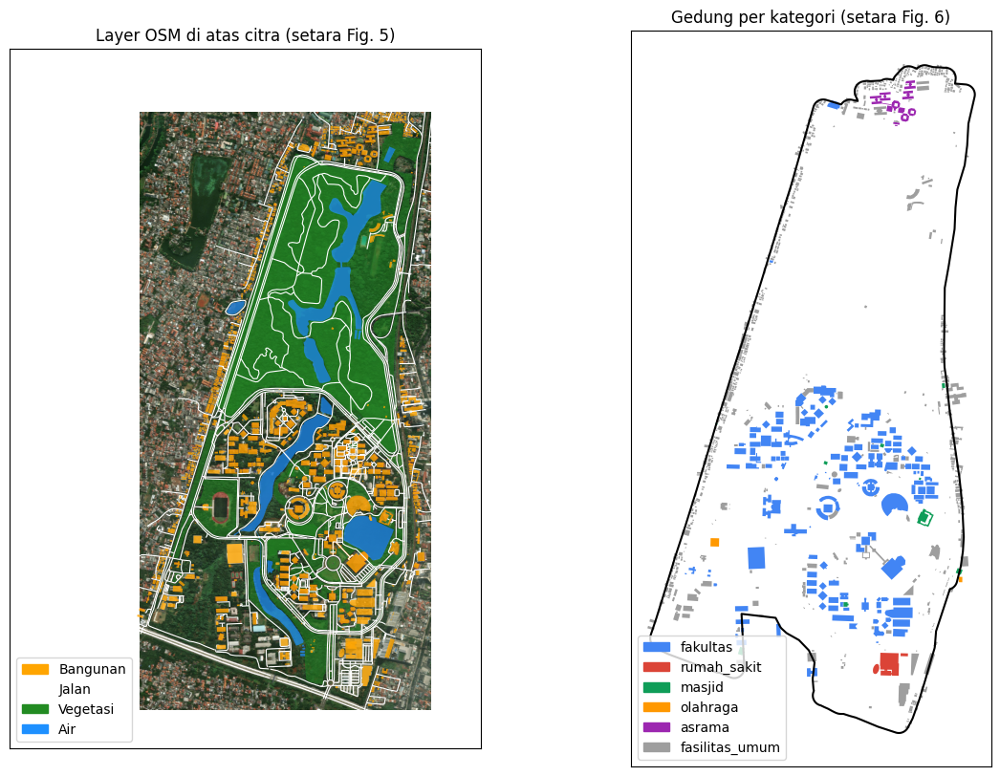

In [6]:
with rasterio.open(img_path) as src:
    f = max(1, src.width // 1500)
    img = src.read(out_shape=(3, src.height // f, src.width // f))
    img_tr = src.transform * src.transform.scale(src.width / img.shape[2], src.height / img.shape[1])

fig, ax = plt.subplots(1, 2, figsize=(14, 10))
show(img, transform=img_tr, ax=ax[0])
vegetation.plot(ax=ax[0], color="forestgreen", alpha=0.5)
water.plot(ax=ax[0], color="dodgerblue", alpha=0.7)
roads.plot(ax=ax[0], color="white", lw=0.8)
buildings.plot(ax=ax[0], color="orange", alpha=0.8)
ax[0].legend(handles=[Patch(color=c, label=l) for c, l in
                      [("orange", "Bangunan"), ("white", "Jalan"), ("forestgreen", "Vegetasi"), ("dodgerblue", "Air")]],
             loc="lower left")
ax[0].set_title("Layer OSM di atas citra (setara Fig. 5)")

aoi_buf.boundary.plot(ax=ax[1], color="k")
for cat, col in CATEGORY_COLORS.items():
    buildings[buildings.category == cat].plot(ax=ax[1], color=np.array(col) / 255)
ax[1].legend(handles=[Patch(color=np.array(c) / 255, label=k) for k, c in CATEGORY_COLORS.items()], loc="lower left")
ax[1].set_title("Gedung per kategori (setara Fig. 6)")
for a in ax:
    a.set_xticks([]); a.set_yticks([])
savefig(fig, "fig05_06_tematik.png")
plt.show()

## 5. Verifikasi visual 25 gedung OSM

Periksa tiap panel: apakah garis kuning pas dengan atap/dasar gedung di citra?
Isi kolom `ok` (1 = sesuai, 0 = tidak) di `interim/verify_sample.csv`, lalu jalankan sel terakhir.

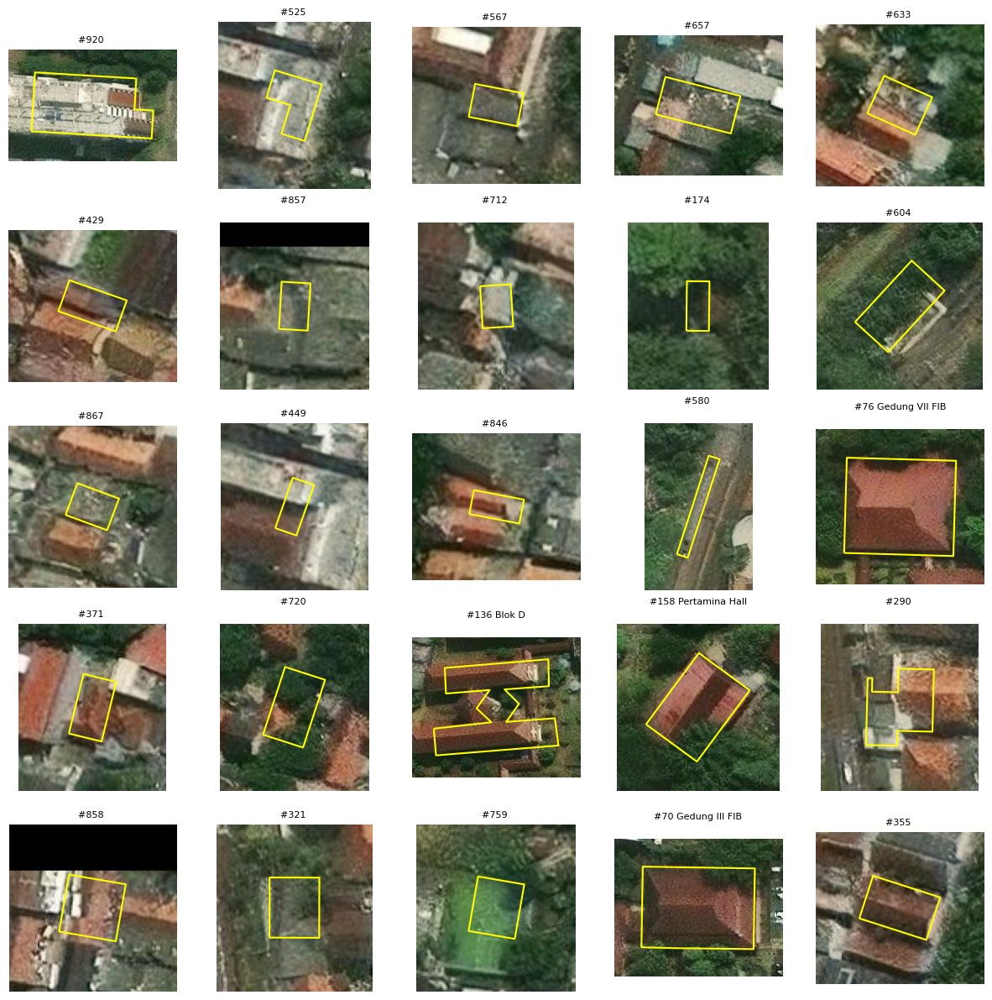

Isi kolom ok di /home/luwes-system/Desktop/bahan ajar 2026/ui3d/interim/verify_sample.csv


In [7]:
n = min(F["verify_sample"], len(buildings))
sample = buildings.sample(n, random_state=CFG["maskrcnn"]["seed"])
cols = 5
fig, axs = plt.subplots(int(np.ceil(n / cols)), cols, figsize=(3 * cols, 3 * np.ceil(n / cols)))
with rasterio.open(img_path) as src:
    for a, (i, r) in zip(axs.ravel(), sample.iterrows()):
        x0, y0, x1, y1 = r.geometry.buffer(10).bounds
        win = rasterio.windows.from_bounds(x0, y0, x1, y1, src.transform)
        show(src.read(window=win, boundless=True), transform=src.window_transform(win), ax=a)
        gpd.GeoSeries([r.geometry]).boundary.plot(ax=a, color="yellow", lw=1.5)
        a.set_title(f"#{i} {str(r.get('name') or '')[:18]}", fontsize=8)
for a in axs.ravel():
    a.axis("off")
savefig(fig, "fig_verifikasi_osm.png")
plt.show()

vpath = interim("verify_sample.csv")
if not vpath.exists():
    pd.DataFrame({"idx": sample.index, "id": sample.get("id"), "name": sample.get("name"), "ok": ""}).to_csv(vpath, index=False)
print("Isi kolom ok di", vpath)

In [8]:
v = pd.read_csv(vpath)
if v.ok.notna().any():
    v = v.dropna(subset=["ok"])
    print(f"OSM sesuai citra: {int(v.ok.sum())}/{len(v)} ({v.ok.mean():.0%})")
else:
    print("verify_sample.csv belum diisi")

verify_sample.csv belum diisi


# 04 — Mask R-CNN (torchvision ResNet50-FPN v2)

Padanan ekstraksi otomatis di paper (Tabel 1, Fig. 8, 16–18).

1. Chip 512×512 px dari `interim/ui_rgb.tif`; instance mask dari layer OSM, dirasterisasi saat dibaca.
   Kelas: 1 Bangunan, 2 Jalan (garis di-buffer sesuai lebar), 3 Vegetasi, 4 Air.
   Label bangunan = OSM + Google Open Buildings v3 yang tidak tumpang tindih dengan OSM (`maskrcnn.label_gob`),
   karena OSM tidak lengkap: gedung nyata tanpa label OSM membuat model belajar bahwa atap = latar.
2. Split 80/20 per blok spasial 4×4 chip agar chip latih dan validasi tidak bertetangga. Chip latih diambil
   dengan stride 256 px (overlap 50%) untuk memperbanyak data, tetapi tidak boleh menyentuh blok validasi.
   Augmentasi: rotasi 90° acak + flip.
3. Mask R-CNN pretrained COCO, head diganti untuk 5 kelas (latar + 4).
4. Latih maks. 8 epoch (replikasi paper) dan 25 epoch (pembanding); loss latih/validasi per batch (Fig. 18).
   Bobot yang dipakai = epoch dengan loss validasi terendah (mencegah overfit). Disk hemat: hanya checkpoint
   epoch terakhir (untuk melanjutkan bila terputus) dan bobot terbaik yang disimpan.
5. Precision/Recall/F1 per kelas pada IoU mask ≥ 0,5 (Tabel 1), contoh deteksi (Fig. 16–17).
6. Inferensi seluruh AOI dengan sliding window → poligon gedung; duplikat antar-window dibuang dengan NMS
   (bukan digabung), simplify 0,5 m; raster kelas (Fig. 8).

**Output**: `models/maskrcnn_ui.pt`, `output/dl_buildings.gpkg`, `output/dl_classes.tif`, `output/dl_metrics.csv`.

Butuh GPU CUDA; di CPU training sangat lambat. Hemat memori untuk GPU kecil (mis. 6 GB): input tidak di-upscale
(`min_size=max_size=512`), mixed precision (AMP), batch 1. Bila tetap OOM: restart kernel dulu agar memori lama lepas.

In [1]:
import shutil
import time

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
import torch
from rasterio.features import rasterize, shapes
from rasterio.windows import Window
import shapely
from shapely.geometry import box, shape
from shapely.ops import unary_union
from torch import nn
from torchvision.models.detection import maskrcnn_resnet50_fpn_v2
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor

from ui3d_common import CFG, CRS, interim, model_path, out, road_polygons, savefig

M = CFG["maskrcnn"]
S = M["chip_px"]
CLASSES = ["latar", "bangunan", "jalan", "vegetasi", "air"]
COLORS = np.array([[0, 0, 0], [255, 140, 0], [255, 255, 255], [34, 139, 34], [30, 144, 255]], np.uint8)
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(M["seed"])
print("Device:", DEV)

Device: cuda


## 1. Instance per kelas dan indeks chip

In [2]:
src = rasterio.open(interim("ui_rgb.tif"))
lay = interim("osm_layers.gpkg")
ref = gpd.read_file(out("ref_buildings.gpkg"))
roads = gpd.read_file(lay, layer="roads")
veg = gpd.read_file(lay, layer="vegetation")
water = gpd.read_file(lay, layer="water")

bld_labels = ref.geometry
if M["label_gob"]:
    gob = gpd.read_file(out("gob_buildings.gpkg"))
    hit = gpd.sjoin(gob[["geometry"]].reset_index(drop=True), ref[["geometry"]].reset_index(drop=True),
                    predicate="intersects")
    g_hit = gob.geometry.values[hit.index.values]
    frac = shapely.area(shapely.intersection(g_hit, ref.geometry.values[hit.index_right.values])) / shapely.area(g_hit)
    ov = pd.Series(frac, index=hit.index.values).groupby(level=0).sum()  # fraksi luas GOB yang tertutup OSM
    extra = gob.reset_index(drop=True).drop(index=ov[ov > M["gob_max_overlap"]].index)
    bld_labels = pd.concat([ref.geometry, extra.geometry], ignore_index=True)
    print(f"Label bangunan: {len(ref)} OSM + {len(extra)} GOB v3 (tidak tumpang tindih OSM)")
parts = [(1, bld_labels), (2, road_polygons(roads)), (3, veg.geometry), (4, water.geometry)]
inst = gpd.GeoDataFrame({"cls": np.concatenate([[k] * len(g) for k, g in parts])},
                        geometry=pd.concat([g for _, g in parts], ignore_index=True), crs=CRS)
sidx = inst.sindex


def chip_box(r, c, h=S, w=S):
    return box(*rasterio.windows.bounds(Window(c, r, w, h), src.transform))


B = S * M["block_chips"]


def grid(stride):
    df = pd.DataFrame([(r, c) for r in range(0, src.height - S + 1, stride) for c in range(0, src.width - S + 1, stride)],
                      columns=["row", "col"])
    df["n_inst"] = [len(sidx.query(chip_box(r, c), predicate="intersects")) for r, c in zip(df.row, df.col)]
    df["nodata_frac"] = [(src.read(1, window=Window(c, r, S, S)) == 0).mean() for r, c in zip(df.row, df.col)]
    return df[(df.n_inst > 0) & (df.nodata_frac < 0.5)].reset_index(drop=True)


def blocks_of(r, c):
    """Semua blok spasial yang disentuh chip (r, c)."""
    return {(i, j) for i in range(r // B, (r + S - 1) // B + 1) for j in range(c // B, (c + S - 1) // B + 1)}


aligned = grid(S)
rng = np.random.default_rng(M["seed"])
blocks = sorted({(r // B, c // B) for r, c in zip(aligned.row, aligned.col)})
val_blocks = {blocks[k] for k in rng.choice(len(blocks), max(1, round(len(blocks) * M["val_fraction"])), replace=False)}
val = aligned[[blocks_of(r, c) <= val_blocks for r, c in zip(aligned.row, aligned.col)]].assign(split="val")
dense = grid(M["train_stride_px"])
train_ = dense[[not (blocks_of(r, c) & val_blocks) for r, c in zip(dense.row, dense.col)]].assign(split="train")
idx = pd.concat([train_, val], ignore_index=True)
idx.to_csv(interim("chips_index.csv"), index=False)
print(idx.split.value_counts().to_dict())

# Area validasi (dipakai bagian 05 agar evaluasi footprint Mask R-CNN tidak memakai area latih).
val_area = unary_union([chip_box(r, c) for r, c in idx.loc[idx.split == "val", ["row", "col"]].values])
gpd.GeoDataFrame(geometry=[val_area], crs=CRS).to_file(interim("dl_val_area.gpkg"), layer="val_area")

Label bangunan: 995 OSM + 355 GOB v3 (tidak tumpang tindih OSM)


{'train': 473, 'val': 39}


## Dataset: rasterisasi instance per chip

In [3]:
class ChipDS(torch.utils.data.Dataset):
    def __init__(self, df, train):
        self.df, self.train = df.reset_index(drop=True), train

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        r, c = int(self.df.row[i]), int(self.df.col[i])
        win = Window(c, r, S, S)
        tr = src.window_transform(win)
        img = src.read(window=win)
        masks, labels = [], []
        for j in sidx.query(chip_box(r, c), predicate="intersects"):
            m = rasterize([(inst.geometry.iloc[j], 1)], out_shape=(S, S), transform=tr, dtype="uint8")
            if m.sum() >= M["min_pixels"]:
                masks.append(m)
                labels.append(inst.cls.iloc[j])
        masks = np.array(masks, np.uint8).reshape(-1, S, S)
        if self.train:  # augmentasi: rotasi 90° acak + flip horizontal
            k = int(torch.randint(4, (1,)))
            img, masks = np.rot90(img, k, (1, 2)), np.rot90(masks, k, (1, 2))
            if torch.rand(1) < 0.5:
                img, masks = img[:, :, ::-1], masks[:, :, ::-1]
        boxes = []
        for m in masks:
            ys, xs = np.where(m)
            boxes.append([xs.min(), ys.min(), xs.max() + 1, ys.max() + 1])
        target = {"boxes": torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4),
                  "labels": torch.tensor(labels, dtype=torch.int64),
                  "masks": torch.from_numpy(masks.copy())}
        return torch.from_numpy(img.copy()).float() / 255, target


def collate(b):
    return tuple(zip(*b))


ds_train, ds_val = ChipDS(idx[idx.split == "train"], True), ChipDS(idx[idx.split == "val"], False)
# num_workers=0: handle rasterio tidak aman dibagi antar proses.
dl_train = torch.utils.data.DataLoader(ds_train, batch_size=M["batch_size"], shuffle=True, collate_fn=collate)
dl_val = torch.utils.data.DataLoader(ds_val, batch_size=M["batch_size"], shuffle=False, collate_fn=collate)
print(len(ds_train), "chip latih;", len(ds_val), "chip validasi")

473 chip latih; 39 chip validasi


## 3–4. Model dan training (8 vs 25 epoch)

In [4]:
def build_model():
    # default torchvision memperbesar gambar ke 800 px; chip 512 dipakai apa adanya agar hemat memori GPU
    m = maskrcnn_resnet50_fpn_v2(weights="DEFAULT", min_size=S, max_size=S)
    m.roi_heads.box_predictor = FastRCNNPredictor(1024, len(CLASSES))
    m.roi_heads.mask_predictor = MaskRCNNPredictor(256, 256, len(CLASSES))
    return m.to(DEV)


def to_dev(imgs, tgs):
    return [i.to(DEV) for i in imgs], [{k: v.to(DEV) for k, v in t.items()} for t in tgs]


def val_by_epoch(log):
    return pd.DataFrame(log).query("split == 'val'").groupby("epoch").loss.mean()


def train(epochs):
    tag = f"e{epochs}"
    final, log_path = model_path(f"maskrcnn_ui_{tag}.pt"), model_path(f"loss_{tag}.csv")
    best_path = model_path(f"maskrcnn_ui_{tag}_best.pt")
    m = build_model()
    if final.exists():
        m.load_state_dict(torch.load(final, map_location=DEV))
        log = pd.read_csv(log_path)
        return m, log, int(val_by_epoch(log).idxmin())
    use_amp = DEV.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    params = [p for p in m.parameters() if p.requires_grad]
    opt = torch.optim.SGD(params, lr=M["lr"], momentum=0.9, weight_decay=5e-4)
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=max(1, epochs * 2 // 3), gamma=0.1)
    start, log = 0, []
    ckpts = sorted(model_path(".").glob(f"maskrcnn_ui_{tag}_ep*.pt"), key=lambda p: int(p.stem.split("_ep")[1]))
    if ckpts:  # lanjutkan dari checkpoint terakhir
        ck = torch.load(ckpts[-1], map_location=DEV, weights_only=False)
        m.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
        start, log = ck["epoch"], ck["log"]
        print("Lanjut dari", ckpts[-1].name)
    for ep in range(start, epochs):
        t0 = time.time()
        m.train()
        for b, (imgs, tgs) in enumerate(dl_train):
            with torch.autocast(DEV.type, dtype=torch.float16, enabled=use_amp):
                loss = sum(m(*to_dev(imgs, tgs)).values())
            opt.zero_grad()
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            log.append(dict(epoch=ep + 1, batch=b, split="train", loss=loss.item()))
        # Loss validasi: torchvision hanya mengembalikan loss di mode train; BatchNorm dibekukan agar tidak bocor.
        for mod in m.modules():
            if isinstance(mod, nn.BatchNorm2d):
                mod.eval()
        with torch.no_grad():
            for b, (imgs, tgs) in enumerate(dl_val):
                with torch.autocast(DEV.type, dtype=torch.float16, enabled=use_amp):
                    loss = sum(m(*to_dev(imgs, tgs)).values())
                log.append(dict(epoch=ep + 1, batch=b, split="val", loss=loss.item()))
        sched.step()
        if val_by_epoch(log).idxmin() == ep + 1:
            torch.save(m.state_dict(), best_path)
        ck = model_path(f"maskrcnn_ui_{tag}_ep{ep + 1}.pt")
        torch.save(dict(model=m.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(), epoch=ep + 1, log=log), ck)
        for old in model_path(".").glob(f"maskrcnn_ui_{tag}_ep*.pt"):
            if old != ck:
                old.unlink()
        ep_log = pd.DataFrame(log).query("epoch == @ep + 1").groupby("split").loss.mean()
        print(f"[{tag}] epoch {ep + 1}/{epochs} train {ep_log['train']:.3f} val {ep_log['val']:.3f} ({time.time() - t0:.0f} s)")
    best_ep = int(val_by_epoch(log).idxmin())
    m.load_state_dict(torch.load(best_path, map_location=DEV))
    torch.save(m.state_dict(), final)
    log = pd.DataFrame(log)
    log.to_csv(log_path, index=False)
    print(f"[{tag}] bobot dipakai: epoch {best_ep} (loss validasi terendah)")
    return m, log, best_ep


models, logs, best_eps = {}, {}, {}
for e in M["epochs"]:
    models[e], logs[e], best_eps[e] = train(e)
    models[e].cpu()  # lepas memori GPU sebelum model berikutnya dilatih
    torch.cuda.empty_cache()

[e8] epoch 1/8 train 2.338 val 2.390 (92 s)


[e8] epoch 2/8 train 2.080 val 2.345 (92 s)


[e8] epoch 3/8 train 1.997 val 2.211 (92 s)


[e8] epoch 4/8 train 1.948 val 2.630 (93 s)


[e8] epoch 5/8 train 1.902 val 2.371 (93 s)


...

[e25] epoch 22/25 train 1.361 val 2.849 (95 s)


[e25] epoch 23/25 train 1.343 val 2.875 (95 s)


[e25] epoch 24/25 train 1.310 val 3.083 (95 s)


[e25] epoch 25/25 train 1.299 val 2.960 (96 s)


[e25] bobot dipakai: epoch 5 (loss validasi terendah)


### Kurva loss per batch (setara Fig. 18)

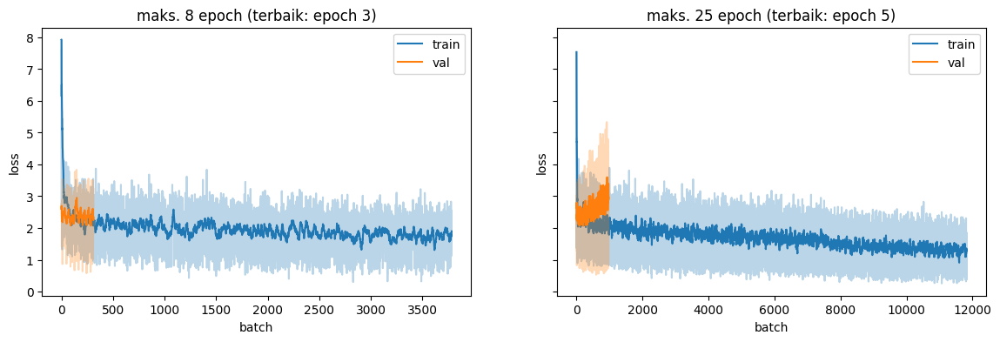

In [5]:
fig, ax = plt.subplots(1, len(logs), figsize=(7 * len(logs), 4), sharey=True)
for a, (e, lg) in zip(np.atleast_1d(ax), logs.items()):
    for split, col in (("train", "tab:blue"), ("val", "tab:orange")):
        s = lg[lg.split == split].loss.reset_index(drop=True)
        a.plot(s, color=col, alpha=0.3)
        a.plot(s.rolling(20, min_periods=1).mean(), color=col, label=split)
    a.set(title=f"maks. {e} epoch (terbaik: epoch {best_eps[e]})", xlabel="batch", ylabel="loss")
    a.legend()
savefig(fig, "fig18_loss.png")
plt.show()

## 5. Precision, Recall, F1 per kelas (IoU mask ≥ 0,5)

In [6]:
@torch.no_grad()
def predict(m, img):
    m.to(DEV).eval()
    p = m([img.to(DEV)])[0]
    keep = p["scores"] >= M["score_threshold"]
    order = torch.argsort(p["scores"][keep], descending=True)
    return ((p["masks"][keep][order, 0] > 0.5).cpu().numpy(), p["labels"][keep][order].cpu().numpy(),
            p["scores"][keep][order].cpu().numpy())


def evaluate(m):
    cnt = {k: dict(TP=0, FP=0, FN=0) for k in range(1, len(CLASSES))}
    for i in range(len(ds_val)):
        img, tg = ds_val[i]
        pm, pl, _ = predict(m, img)
        gm, gl = tg["masks"].numpy().astype(bool), tg["labels"].numpy()
        for k in cnt:
            P, G = pm[pl == k], gm[gl == k]
            used, tp = np.zeros(len(G), bool), 0
            for pmask in P:  # greedy berdasarkan skor tertinggi
                if not len(G):
                    break
                iou = (G & pmask).sum((1, 2)) / np.maximum((G | pmask).sum((1, 2)), 1)
                iou[used] = 0
                j = iou.argmax()
                if iou[j] >= M["iou_threshold"]:
                    used[j], tp = True, tp + 1
            cnt[k]["TP"] += tp; cnt[k]["FP"] += len(P) - tp; cnt[k]["FN"] += len(G) - tp
    rows = []
    for k, c in cnt.items():
        p = c["TP"] / max(c["TP"] + c["FP"], 1)
        r = c["TP"] / max(c["TP"] + c["FN"], 1)
        rows.append(dict(kelas=CLASSES[k], **c, precision=p, recall=r, f1=2 * p * r / max(p + r, 1e-9)))
    return pd.DataFrame(rows)


metrics = pd.concat([evaluate(m).assign(epochs=e, best_epoch=best_eps[e]) for e, m in models.items()],
                    ignore_index=True).round(3)
paper = {"bangunan": (0.78, 0.86, 0.82), "jalan": (0.62, 0.875, 0.73), "vegetasi": (0.89, 0.96, 0.93)}
metrics["paper_P_R_F1"] = metrics.kelas.map(paper)
metrics.to_csv(out("dl_metrics.csv"), index=False)
metrics

,kelas,TP,FP,FN,precision,recall,f1,epochs,best_epoch,paper_P_R_F1
0,bangunan,77,142,339,0.352,0.185,0.243,8,3,"(0.78, 0.86, 0.82)"
1,jalan,0,58,349,0.000,0.000,0.000,8,3,"(0.62, 0.875, 0.73)"
2,vegetasi,12,58,87,0.171,0.121,0.142,8,3,"(0.89, 0.96, 0.93)"
3,air,3,9,14,0.250,0.176,0.207,8,3,NaN
4,bangunan,77,127,339,0.377,0.185,0.248,25,5,"(0.78, 0.86, 0.82)"
5,jalan,1,82,348,0.012,0.003,0.005,25,5,"(0.62, 0.875, 0.73)"
6,vegetasi,15,66,84,0.185,0.152,0.167,25,5,"(0.89, 0.96, 0.93)"
7,air,5,4,12,0.556,0.294,0.385,25,5,NaN


In [7]:
# Model terbaik (F1 bangunan) dipakai untuk inferensi dan disalin ke models/maskrcnn_ui.pt.
best_e = int(metrics[metrics.kelas == "bangunan"].sort_values("f1").epochs.iloc[-1])
best = models[best_e]
shutil.copy(model_path(f"maskrcnn_ui_e{best_e}.pt"), model_path("maskrcnn_ui.pt"))
print("Model terbaik:", best_e, "epoch")

Model terbaik: 25 epoch


### Contoh deteksi (setara Fig. 16–17): referensi OSM vs prediksi

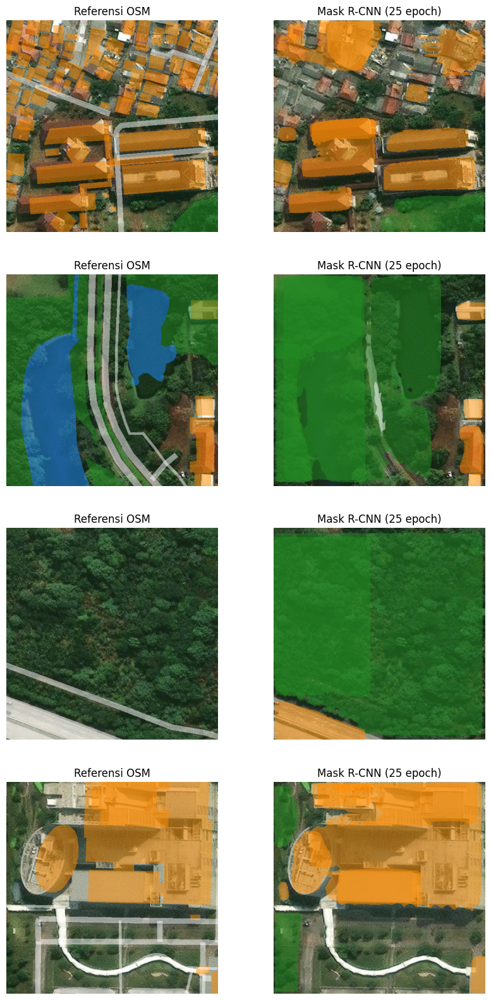

In [8]:
def overlay(img, masks, labels):
    o = img.copy()
    for m, k in zip(masks, labels):
        o[m] = (0.5 * o[m] + 0.5 * COLORS[k]).astype(np.uint8)
    return o


sel = np.linspace(0, len(ds_val) - 1, min(4, len(ds_val))).astype(int)
fig, axs = plt.subplots(len(sel), 2, figsize=(10, 5 * len(sel)), squeeze=False)
for row, i in zip(axs, sel):
    img, tg = ds_val[i]
    rgb = (img.permute(1, 2, 0).numpy() * 255).astype(np.uint8)
    pm, pl, _ = predict(best, img)
    row[0].imshow(overlay(rgb, tg["masks"].numpy().astype(bool), tg["labels"].numpy())); row[0].set_title("Referensi OSM")
    row[1].imshow(overlay(rgb, pm, pl)); row[1].set_title(f"Mask R-CNN ({best_e} epoch)")
    for a in row:
        a.axis("off")
savefig(fig, "fig16_17_contoh_deteksi.png")
plt.show()

## 6. Inferensi seluruh AOI (sliding window)

Raster kelas: tiap piksel diberi kelas instance dengan skor tertinggi. Poligon gedung dari mask instance.
Duplikat antar-window dibuang dengan NMS: urut skor, buang poligon yang IoU ≥ 0,5 atau ≥ 70% luasnya
tertutup poligon berskor lebih tinggi. Gedung berdempetan tidak lagi dilebur jadi satu.

In [9]:
step = S - M["overlap_px"]
cls_r = np.zeros((src.height, src.width), np.uint8)
score_r = np.zeros((src.height, src.width), np.float32)
polys = []
t0 = time.time()
for r in range(0, src.height, step):
    for c in range(0, src.width, step):
        win = Window(c, r, min(S, src.width - c), min(S, src.height - r))
        img = src.read(window=win)
        if img.max() == 0:
            continue
        pm, pl, ps = predict(best, torch.from_numpy(img).float() / 255)
        sl = (slice(r, r + win.height), slice(c, c + win.width))
        wtr = src.window_transform(win)
        for m, k, s in zip(pm, pl, ps):
            upd = m & (s > score_r[sl])
            cls_r[sl][upd], score_r[sl][upd] = k, s
            if k == 1:
                polys += [(shape(g), s) for g, _ in shapes(m.astype(np.uint8), mask=m, transform=wtr)]
print(f"Inferensi {time.time() - t0:.0f} s")

prof = dict(driver="GTiff", height=src.height, width=src.width, count=1, dtype="uint8", crs=CRS,
            transform=src.transform, compress="deflate", tiled=True)
with rasterio.open(out("dl_classes.tif"), "w", **prof) as d:
    d.write(cls_r, 1)

cand = gpd.GeoDataFrame({"score": [s for _, s in polys]}, geometry=[g.buffer(0) for g, _ in polys], crs=CRS)
cand = cand[cand.area >= CFG["footprint"]["min_area_m2"]].sort_values("score", ascending=False).reset_index(drop=True)
geoms = cand.geometry.values
tree, keep = shapely.STRtree(geoms), np.ones(len(cand), bool)
for i, g in enumerate(geoms):
    if not keep[i]:
        continue
    for j in tree.query(g, predicate="intersects"):
        if j > i and keep[j]:
            inter = g.intersection(geoms[j]).area
            if inter / g.union(geoms[j]).area >= 0.5 or inter / min(g.area, geoms[j].area) >= 0.7:
                keep[j] = False
dl_bld = cand[keep].copy()
dl_bld["geometry"] = dl_bld.simplify(CFG["maskrcnn"]["simplify_m"])
dl_bld = dl_bld.reset_index(drop=True)
print(f"NMS: {len(cand)} kandidat → {len(dl_bld)} gedung")
dl_bld["footprint_source"] = f"MaskRCNN_e{best_e}"
dl_bld.to_file(out("dl_buildings.gpkg"), layer="dl_buildings")
print(len(dl_bld), "gedung hasil Mask R-CNN")

Inferensi 49 s


NMS: 2705 kandidat → 1803 gedung
1803 gedung hasil Mask R-CNN


### Raster klasifikasi AOI (setara Fig. 8)

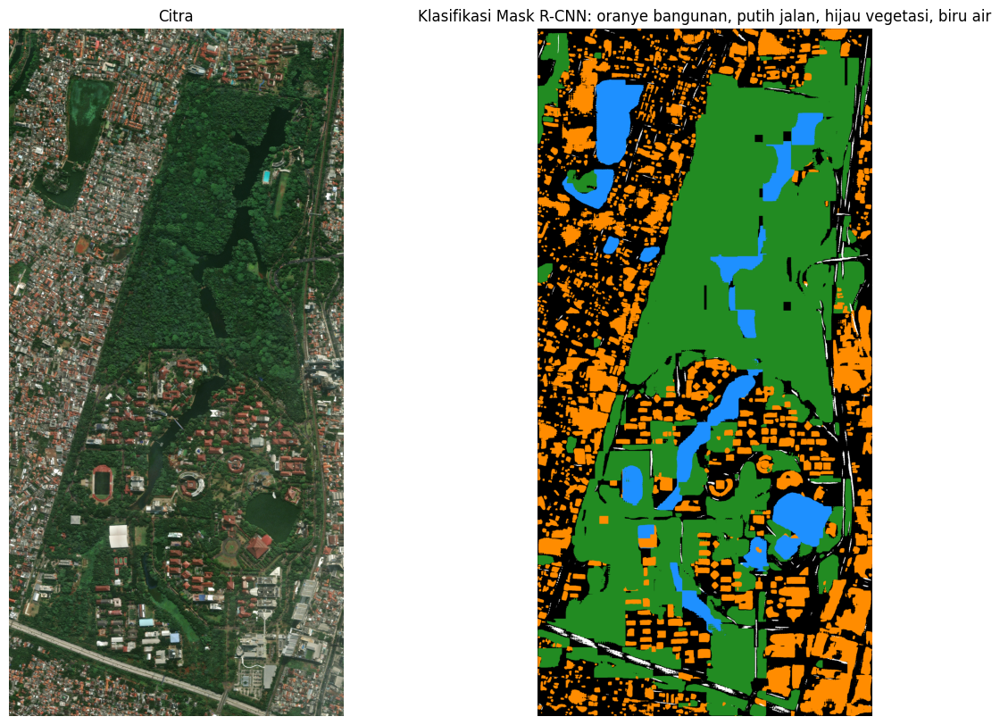

In [10]:
f = max(1, src.width // 1500)
fig, ax = plt.subplots(1, 2, figsize=(14, 10))
ax[0].imshow(src.read(out_shape=(3, src.height // f, src.width // f)).transpose(1, 2, 0))
ax[0].set_title("Citra")
ax[1].imshow(COLORS[cls_r[::f, ::f]])
ax[1].set_title("Klasifikasi Mask R-CNN: oranye bangunan, putih jalan, hijau vegetasi, biru air")
for a in ax:
    a.axis("off")
savefig(fig, "fig08_klasifikasi.png")
plt.show()

# 05 — Evaluasi footprint

Padanan Tabel 2 dan Fig. 19 paper. Referensi: footprint OSM (pengganti total station).

1. Tiap gedung referensi dipasangkan dengan kandidat (GOB v3, Mask R-CNN) ber-IoU tertinggi.
2. Jarak `d` per pasangan: pergeseran centroid dan jarak rata-rata vertex kandidat ke batas referensi; RMSE (Pers. 2).
3. Distorsi luas (Tabel 2): `(A_ref − A_i) / A_ref × 100%`.
4. Peta pergeseran dan analisis penyebab (relief displacement, bayangan, kanopi).
5. Opsional: referensi GNSS/total station bila ada.

Mask R-CNN dilatih dari OSM, jadi evaluasi yang adil hanya di **area validasi** (`interim/dl_val_area.gpkg`).

**Output**: `output/footprint_eval.csv`, `output/footprint_pairs.gpkg`, peta pergeseran.

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely
from scipy.stats import spearmanr

from ui3d_common import CFG, interim, out, raw, savefig, zonal

F = CFG["footprint"]
ref = gpd.read_file(out("ref_buildings.gpkg"))
cands = {"GOB_v3": gpd.read_file(out("gob_buildings.gpkg"))}
if out("dl_buildings.gpkg").exists():
    cands["MaskRCNN"] = gpd.read_file(out("dl_buildings.gpkg"))
val_area = gpd.read_file(interim("dl_val_area.gpkg")).geometry.iloc[0] if interim("dl_val_area.gpkg").exists() else None
{k: len(v) for k, v in cands.items()}

{'GOB_v3': 1254, 'MaskRCNN': 1803}

## 1–2. Pasangan IoU tertinggi dan jarak

In [2]:
def match(ref, cand):
    j = gpd.sjoin(ref[["geometry"]].reset_index(names="rid"), cand[["geometry"]].reset_index(names="cid"),
                  predicate="intersects")
    rg, cg = ref.geometry.values[j.rid.values], cand.geometry.values[j.cid.values]
    j["iou"] = shapely.area(shapely.intersection(rg, cg)) / shapely.area(shapely.union(rg, cg))
    best = j.sort_values("iou").groupby("rid").tail(1).sort_values("rid")
    rg, cg = ref.geometry.values[best.rid.values], cand.geometry.values[best.cid.values]
    best["shift_centroid_m"] = shapely.distance(shapely.centroid(rg), shapely.centroid(cg))
    best["vertex_dist_m"] = [np.mean(shapely.distance(r.exterior,shapely.points(np.asarray(c.exterior.coords)[:-1])))
                             for r, c in zip(rg, cg)]
    best["area_ref"], best["area_cand"] = shapely.area(rg), shapely.area(cg)
    best["distortion_pct"] = (best.area_ref - best.area_cand) / best.area_ref * 100
    return gpd.GeoDataFrame(best.drop(columns="geometry"), geometry=cg, crs=ref.crs)


def summarize(ref, cand, pairs, name, area):
    p = pairs[pairs.iou >= F["match_iou"]]
    rmse = lambda d: float(np.sqrt(np.mean(np.square(d)))) if len(d) else np.nan  # noqa: E731
    return dict(sumber=name, area=area, n_ref=len(ref), n_kandidat=len(cand), n_pasangan=len(p),
                tingkat_deteksi_pct=len(p) / max(len(ref), 1) * 100, iou_median=p.iou.median(),
                rmse_centroid_m=rmse(p.shift_centroid_m), rmse_vertex_m=rmse(p.vertex_dist_m),
                distorsi_pasangan_pct=(p.area_ref.sum() - p.area_cand.sum()) / p.area_ref.sum() * 100 if len(p) else np.nan,
                distorsi_total_pct=(ref.area.sum() - cand.area.sum()) / ref.area.sum() * 100)


rows, all_pairs = [], []
for name, cand in cands.items():
    areas = [("AOI", None)] + ([("val", val_area)] if val_area is not None else [])
    for area_name, geom in areas:
        r = ref if geom is None else ref[ref.centroid.within(geom)]
        c = cand if geom is None else cand[cand.centroid.within(geom)]
        pairs = match(r.reset_index(drop=True), c.reset_index(drop=True))
        rows.append(summarize(r, c, pairs, name, area_name))
        if area_name == "AOI":
            all_pairs.append(pairs.assign(sumber=name))
ev = pd.DataFrame(rows).round(3)
ev.to_csv(out("footprint_eval.csv"), index=False)
print(f"Paper: digitasi manual RMSE 3,7 m, distorsi 4,61%; deep learning distorsi 17,12%. Pasangan: IoU >= {F['match_iou']}")
ev

Paper: digitasi manual RMSE 3,7 m, distorsi 4,61%; deep learning distorsi 17,12%. Pasangan: IoU >= 0.3


,sumber,area,n_ref,n_kandidat,n_pasangan,tingkat_deteksi_pct,iou_median,rmse_centroid_m,rmse_vertex_m,distorsi_pasangan_pct,distorsi_total_pct
0,GOB_v3,AOI,995,1254,516,51.859,0.519,5.675,3.722,-0.357,-7.204
1,GOB_v3,val,249,320,131,52.610,0.517,5.261,3.863,-4.883,-7.177
2,MaskRCNN,AOI,995,1803,281,28.241,0.629,6.406,3.425,11.417,-155.251
3,MaskRCNN,val,249,168,63,25.301,0.672,7.490,4.548,-6.279,-55.117


In [3]:
pairs = pd.concat(all_pairs, ignore_index=True)
pairs = gpd.GeoDataFrame(pairs, geometry="geometry", crs=ref.crs)
pairs.to_file(out("footprint_pairs.gpkg"), layer="pairs")

## Peta pergeseran (setara Fig. 19)

Panah = pergeseran centroid referensi → kandidat (dibesarkan 5×). Zoom 400 × 400 m di sekitar gedung OSM terbesar.

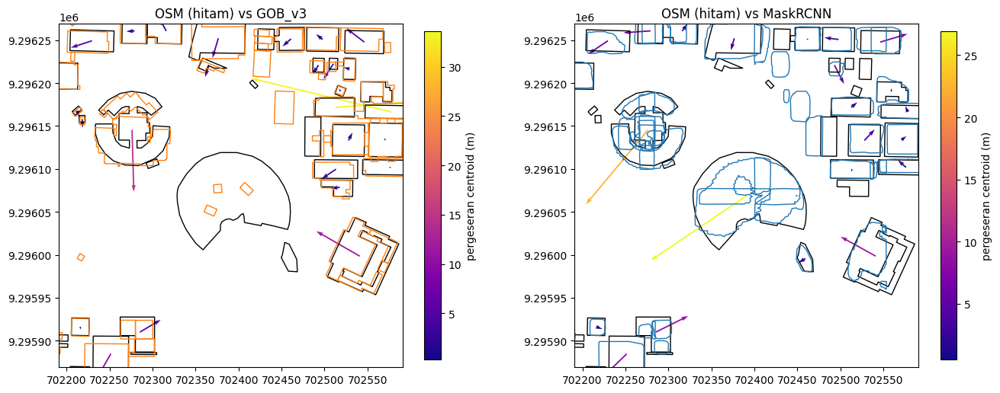

In [4]:
cx, cy = ref.loc[ref.area.idxmax()].geometry.centroid.coords[0]
ext = (cx - 200, cy - 200, cx + 200, cy + 200)
colors = {"GOB_v3": "tab:orange", "MaskRCNN": "tab:blue"}
fig, axs = plt.subplots(1, len(cands), figsize=(8 * len(cands), 8), squeeze=False)
for a, name in zip(axs[0], cands):
    p = pairs[(pairs.sumber == name) & (pairs.iou >= F["match_iou"])].cx[ext[0]:ext[2], ext[1]:ext[3]]
    ref.cx[ext[0]:ext[2], ext[1]:ext[3]].boundary.plot(ax=a, color="k", lw=1)
    cands[name].cx[ext[0]:ext[2], ext[1]:ext[3]].boundary.plot(ax=a, color=colors[name], lw=1)
    rc = shapely.centroid(ref.geometry.values[p.rid.values])
    pc = shapely.centroid(p.geometry.values)
    x, y = shapely.get_x(rc), shapely.get_y(rc)
    q = a.quiver(x, y, (shapely.get_x(pc) - x) * 5, (shapely.get_y(pc) - y) * 5, p.shift_centroid_m,
                 angles="xy", scale_units="xy", scale=1, cmap="plasma", width=0.004)
    plt.colorbar(q, ax=a, label="pergeseran centroid (m)", shrink=0.7)
    a.set(xlim=(ext[0], ext[2]), ylim=(ext[1], ext[3]), title=f"OSM (hitam) vs {name}")
    a.set_aspect("equal")
savefig(fig, "fig19_pergeseran.png")
plt.show()

## Analisis penyebab

- **Relief displacement atap**: citra satelit off-nadir menggeser atap gedung tinggi menjauhi titik nadir.
  Bila ini dominan, pergeseran naik dengan tinggi gedung (tinggi dari Open Buildings 2.5D) dan arahnya seragam.
- **Bayangan** memperbesar footprint ke satu arah (distorsi luas negatif); **kanopi pohon** memotong footprint
  (distorsi positif, gedung hilang). Periksa visual di peta pergeseran dan contoh deteksi bagian 04.

In [5]:
h = zonal(ref, raw("gob_25d"), np.median, band=2)
for name in cands:
    p = pairs[(pairs.sumber == name) & (pairs.iou >= F["match_iou"])]
    hh = h[p.rid.values]
    ok = np.isfinite(hh)
    rho, pv = spearmanr(hh[ok], p.shift_centroid_m.values[ok])
    dx = shapely.get_x(shapely.centroid(p.geometry.values)) - shapely.get_x(shapely.centroid(ref.geometry.values[p.rid.values]))
    dy = shapely.get_y(shapely.centroid(p.geometry.values)) - shapely.get_y(shapely.centroid(ref.geometry.values[p.rid.values]))
    print(f"{name}: Spearman(tinggi, pergeseran) = {rho:.2f} (p={pv:.3f}); "
          f"rata-rata vektor geser dx={dx.mean():.2f} m, dy={dy.mean():.2f} m; "
          f"distorsi median {p.distortion_pct.median():.1f}%")

GOB_v3: Spearman(tinggi, pergeseran) = 0.19 (p=0.000); rata-rata vektor geser dx=-0.61 m, dy=-0.92 m; distorsi median -7.6%
MaskRCNN: Spearman(tinggi, pergeseran) = 0.17 (p=0.004); rata-rata vektor geser dx=-0.59 m, dy=-0.63 m; distorsi median 1.0%


## Opsional: referensi GNSS RTK / total station

Bila ada titik sudut gedung hasil survei di `raw/gnss_corners.gpkg` (titik, CRS apa pun), sel ini menghitung
RMSE jarak tiap titik ke vertex OSM terdekat, sehingga OSM ikut dievaluasi.

In [6]:
gnss_path = raw("osm").parent / "gnss_corners.gpkg"
if gnss_path.exists():
    gnss = gpd.read_file(gnss_path).to_crs(ref.crs)
    verts = shapely.points(np.vstack([np.asarray(g.exterior.coords) for g in ref.geometry]))
    tree = shapely.STRtree(verts)
    d = shapely.distance(gnss.geometry.values, verts[tree.nearest(gnss.geometry.values)])
    print(f"OSM vs GNSS: n={len(d)}, RMSE={np.sqrt(np.mean(d ** 2)):.2f} m, maks={d.max():.2f} m")
else:
    print("Tidak ada raw/gnss_corners.gpkg — dilewati")

Tidak ada raw/gnss_corners.gpkg — dilewati


# 06 — Tinggi bangunan dan geodatabase

1. Jumlah lantai total `levels` dari OSM `building:levels`; bila kosong, dari median tinggi Open Buildings 2.5D
   di footprint.
2. `Bld_Height = GFl + Fl × N + 1,0` (Pers. 1). Di sini `N` = jumlah lantai **di atas lantai dasar**
   (`levels − 1`), karena lantai dasar sudah dihitung lewat `GFl`. Dengan `N = levels` (PRD awal) satu lantai
   terhitung dua kali: gedung 1 lantai jadi 8,5 m padahal 2.5D ±5 m. Dari tinggi 2.5D:
   `N = max(0, round((h − GFl − 1,0) / Fl))`.
3. Elevasi dasar = persentil 10 DEM 8 m di footprint, agar gedung menempel ke terrain.
4. Atribut non-spasial: nama, kategori, sumber footprint.
5. Semua layer ke satu GeoPackage `output/ui3d.gpkg`.

**Output**: `ui3d.gpkg` (aoi, buildings, roads, water, vegetation, terrain_points, + gob/dl buildings bila ada).

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ui3d_common import CFG, aoi, interim, out, raw, savefig, zonal

Bc = CFG["building"]
GFl, Fl, K = Bc["GFl"], Bc["Fl"], Bc["roof_const"]
b = gpd.read_file(out("ref_buildings.gpkg"))

## 1–2. Jumlah lantai dan tinggi

In [2]:
lv = pd.to_numeric(b.get("building:levels", pd.Series(np.nan, index=b.index)), errors="coerce")
h25 = zonal(b, raw("gob_25d"), np.median, band=2)  # band 2 = building_height (m)
N_25d = np.maximum(0, np.round((h25 - GFl - K) / Fl))

b["h_25d_m"] = np.round(h25, 2)
b["N"] = np.where(lv > 0, np.round(lv) - 1, np.where(np.isfinite(N_25d), N_25d, 0)).astype(int)
b["levels"] = b.N + 1
b["N_source"] = np.where(lv > 0, "OSM building:levels", np.where(np.isfinite(N_25d), "OpenBuildings2.5D", "default=0"))
b["Bld_Height"] = GFl + Fl * b.N + K
print(b.N_source.value_counts().to_string())
b[["levels", "N", "Bld_Height"]].describe().T

N_source
OpenBuildings2.5D      880
OSM building:levels    115


,count,mean,std,min,25%,50%,75%,max
levels,995.0,1.667337,1.943075,1.0,1.0,1.0,2.0,29.0
N,995.0,0.667337,1.943075,0.0,0.0,0.0,1.0,28.0
Bld_Height,995.0,7.335678,6.800764,5.0,5.0,5.0,8.5,103.0


## 3. Elevasi dasar dari DEM (persentil 10)

In [3]:
dem = out("dem_ui_8m.tif")
b["base_elev"] = np.round(zonal(b, dem, lambda v: np.percentile(v, Bc["base_elev_percentile"])), 2)
print("Gedung tanpa elevasi dasar:", int(b.base_elev.isna().sum()))

Gedung tanpa elevasi dasar: 0


## 4. Atribut non-spasial dan cek konsistensi

Bld_Height − tinggi 2.5D: median 0.52 m, MAE 1.87 m (n=995)


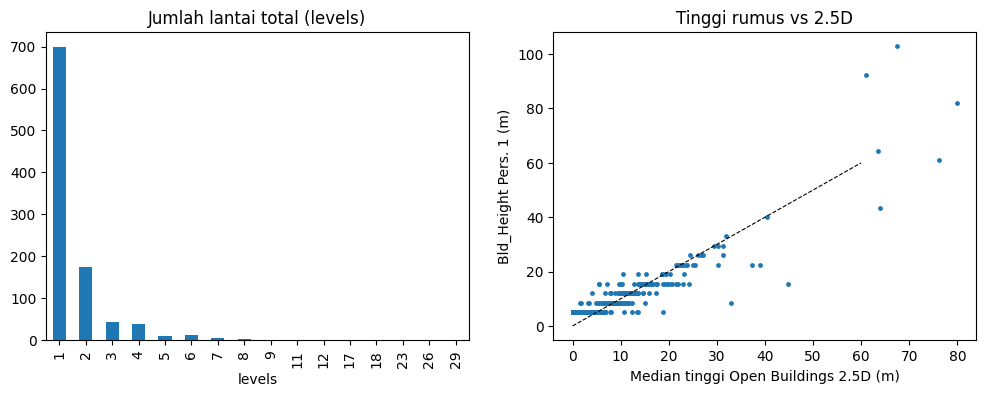

In [4]:
b["name"] = b["name"].fillna("")
cols = ["id", "name", "category", "building", "footprint_source", "area_m2", "levels", "N", "N_source", "h_25d_m",
        "Bld_Height", "base_elev", "geometry"]
buildings = b[[c for c in cols if c in b.columns]]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
buildings.levels.value_counts().sort_index().plot.bar(ax=ax[0], title="Jumlah lantai total (levels)")
ok = buildings.h_25d_m.notna()
ax[1].scatter(buildings.h_25d_m[ok], buildings.Bld_Height[ok], s=6)
ax[1].plot([0, 60], [0, 60], "k--", lw=0.8)
ax[1].set(xlabel="Median tinggi Open Buildings 2.5D (m)", ylabel="Bld_Height Pers. 1 (m)",
          title="Tinggi rumus vs 2.5D")
savefig(fig, "fig_tinggi_bangunan.png")
d = (buildings.Bld_Height - buildings.h_25d_m)[ok]
print(f"Bld_Height − tinggi 2.5D: median {d.median():.2f} m, MAE {d.abs().mean():.2f} m (n={ok.sum()})")
plt.show()

## 5. Tulis geodatabase `ui3d.gpkg`

In [5]:
gdb = out("ui3d.gpkg")
gdb.unlink(missing_ok=True)
lay = interim("osm_layers.gpkg")
layers = {"aoi": aoi("aoi"), "buildings": buildings,
          "roads": gpd.read_file(lay, layer="roads"), "water": gpd.read_file(lay, layer="water"),
          "vegetation": gpd.read_file(lay, layer="vegetation"),
          "terrain_points": gpd.read_file(interim("terrain_points.gpkg"))}
for name, path in (("gob_buildings", out("gob_buildings.gpkg")), ("dl_buildings", out("dl_buildings.gpkg"))):
    if path.exists():
        layers[name] = gpd.read_file(path)
for name, g in layers.items():
    g.to_file(gdb, layer=name)
    print(f"{name:15s} {len(g):6d} fitur")

aoi                  1 fitur


buildings          995 fitur
roads              863 fitur


water               19 fitur


vegetation         118 fitur
terrain_points    1249 fitur


gob_buildings     1254 fitur


dl_buildings      1803 fitur


# 07 — Pemodelan prosedural 3D (pengganti CityEngine + CGA)

Aturan CGA diganti "rule file" Python (dict per kategori), dijalankan berurutan seperti CGA:

1. `extrude(footprint, H, z0)` → blok **LOD1**, digeser ke elevasi dasar.
2. `comp(block, footprint)` → atap (normal ke atas) dan fasad (daftar dinding: segmen + rentang z).
3. `split_floors(wall)` → lantai dasar `GFl`, lantai `Fl`, sisa parapet +1,0 m.
4. `split_tiles(wall, rule)` → tile dinding/jendela/pintu; pintu di lantai dasar fasad terpanjang;
   jendela = kotak tipis tertanam 0,15 m ke dinding (muka luar 2 cm di depan dinding agar terlihat) → **LOD2**.
5. `texture` → dinding diberi tekstur generik buatan PIL lewat UV (bukan foto berhak cipta).
6. Terrain DEM jadi mesh bertekstur citra; jalan dan air di-drape di atas terrain. Kampus memakai citra z19
   (0,3 m); cincin `context_m` di sekelilingnya memakai citra konteks z17 (~1,2 m) agar model tidak berakhir
   di tepi kotak AOI. Tekstur terrain disimpan JPEG di GLB (PNG ~5× lebih besar). Badan air di-*hydro-flatten*:
   muka air datar per danau, DEM di bawahnya diturunkan agar tepian DSM (kanopi) tidak menutupi air.
7. Ekspor `ui_lod1.glb`, `ui_lod1.obj`, `ui_lod2.glb` (Y-up sesuai glTF) dan catat waktu generate.
8. Analisis: Sky View Factor (SVF) dari DSM model 1 m (DTM + gedung LOD1) → `output/svf_1m.tif`.

Koordinat model lokal: x/y relatif ke titik asal AOI, z relatif ke `z_ref`; disimpan di `output/origin.json`.

In [1]:
import io
import json
import time

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import rasterio
import rasterio.features
import trimesh
from PIL import Image, ImageDraw
from pyproj import Transformer
from rasterio.enums import Resampling
from rasterio.transform import from_origin
from rasterio.vrt import WarpedVRT
from rasterio.warp import reproject
from scipy.interpolate import RegularGridInterpolator
from shapely import affinity
from shapely.geometry.polygon import orient
from shapely.ops import unary_union
from trimesh.visual import TextureVisuals

from ui3d_common import (CATEGORY_COLORS, CFG, CRS, aoi, dsm_to_dtm, fig_path, interim, out, raw, road_polygons,
                         savefig)

Bc = CFG["building"]
GFl, Fl, K = Bc["GFl"], Bc["Fl"], Bc["roof_const"]
gdb = out("ui3d.gpkg")
bld = gpd.read_file(gdb, layer="buildings").dropna(subset=["base_elev"]).reset_index(drop=True)
aoi_buf = aoi("aoi_buf50")

## Rule file (pengganti file CGA)

In [2]:
BASE_RULE = dict(tile_w=3.5, win_w=1.6, win_ratio=0.45, door_w=2.2, door_h=2.8,
                 window=[60, 80, 100], door=[90, 60, 40], roof=[120, 120, 120])
RULES = {
    "fakultas": dict(BASE_RULE, tile_w=3.2, win_w=1.8, win_ratio=0.5, roof=[150, 70, 50]),
    "rumah_sakit": dict(BASE_RULE, tile_w=3.0, win_w=1.4, roof=[200, 200, 200]),
    "masjid": dict(BASE_RULE, tile_w=4.0, win_w=1.2, win_ratio=0.6, door_w=3.0, door_h=3.2, roof=[30, 110, 70]),
    "olahraga": dict(BASE_RULE, tile_w=6.0, win_w=3.0, win_ratio=0.3, door_w=3.5, door_h=3.2, roof=[90, 100, 120]),
    "asrama": dict(BASE_RULE, tile_w=3.0, win_w=1.2, roof=[160, 80, 60]),
    "fasilitas_umum": dict(BASE_RULE),
}
INSET, OUT_OFFSET = 0.15, 0.02  # kedalaman jendela ke dalam dinding, tonjolan muka luar
TEX_M = 3.0                     # satu tekstur dinding mencakup 3 × 3 m

## Titik asal lokal dan helper mesh

In [3]:
c = aoi_buf.geometry.iloc[0].centroid
OX, OY = round(c.x), round(c.y)
with rasterio.open(out("dem_ui_8m.tif")) as s:
    win = rasterio.windows.from_bounds(*aoi_buf.total_bounds, s.transform).round_offsets().round_lengths()
    DEM = s.read(1, window=win)
    DEM_TR = s.window_transform(win)
DEM = np.where(np.isnan(DEM), np.nanmean(DEM), DEM)
Z_REF = float(np.floor(np.percentile(DEM, 1)))
lon, lat = Transformer.from_crs(CRS, "EPSG:4326", always_xy=True).transform(OX, OY)
json.dump(dict(x=OX, y=OY, z_ref=Z_REF, crs=CRS, lon=lon, lat=lat), open(out("origin.json"), "w"), indent=1)

ny, nx = DEM.shape
xs = DEM_TR.c + (np.arange(nx) + 0.5) * DEM_TR.a
ys = DEM_TR.f + (np.arange(ny) + 0.5) * DEM_TR.e
_interp = RegularGridInterpolator((ys[::-1], xs), DEM[::-1], bounds_error=False, fill_value=None)

# Grid DEM yang sama, diperlebar CTX m: offset piksel bulat → simpul kampus dan cincin berimpit (tanpa celah).
CTX = Bc["context_m"]
with rasterio.open(out("dem_ui_8m.tif")) as s:
    b = aoi_buf.total_bounds + np.r_[-CTX, -CTX, CTX, CTX]
    win = rasterio.windows.from_bounds(*b, s.transform).round_offsets().round_lengths()
    DEM_CTX = s.read(1, window=win)
    CTX_TR = s.window_transform(win)
DEM_CTX = np.where(np.isnan(DEM_CTX), np.nanmean(DEM_CTX), DEM_CTX)
cxs = CTX_TR.c + (np.arange(DEM_CTX.shape[1]) + 0.5) * CTX_TR.a
cys = CTX_TR.f + (np.arange(DEM_CTX.shape[0]) + 0.5) * CTX_TR.e


def dem_z(x, y):
    """Elevasi DEM (relatif Z_REF) di koordinat UTM."""
    return _interp(np.column_stack([y, x])) - Z_REF


class MeshBuilder:
    """Kumpulkan banyak potongan geometri jadi satu mesh (lebih cepat dari concatenate ribuan Trimesh)."""

    def __init__(self):
        self.v, self.f, self.c, self.uv, self.n = [], [], [], [], 0

    def add(self, v, f, color=None, uv=None):
        self.v.append(np.asarray(v, float))
        self.f.append(np.asarray(f) + self.n)
        self.n += len(v)
        if color is not None:
            self.c.append(np.tile(np.r_[color, 255], (len(f), 1)))
        if uv is not None:
            self.uv.append(np.asarray(uv, float))

    def mesh(self, image=None):
        if not self.v:
            return None
        m = trimesh.Trimesh(np.vstack(self.v), np.vstack(self.f), process=False)
        if image is not None:
            m.visual = TextureVisuals(uv=np.vstack(self.uv), image=image)
        elif self.c:
            m.visual.face_colors = np.vstack(self.c).astype(np.uint8)
        return m


_BOX = trimesh.creation.box(extents=(2, 2, 2))
EZ = np.array([0.0, 0.0, 1.0])


def oriented_box(center, u, n, half):
    """Kotak dengan sumbu (n, u, z) — basis tangan kanan agar winding template tetap benar."""
    V = _BOX.vertices
    return center + V[:, [0]] * half[0] * n + V[:, [1]] * half[1] * u + V[:, [2]] * half[2] * EZ


def local(poly):
    return orient(affinity.translate(poly, -OX, -OY), 1.0)

## Operasi prosedural: extrude → comp → split → texture

In [4]:
def extrude(poly, H, z0):
    m = trimesh.creation.extrude_polygon(poly, H)
    m.apply_translation([0, 0, z0])
    return m


def comp(block, poly):
    """Atap = face dengan normal ke atas; fasad = dinding per segmen ring (luar dan lubang)."""
    roof = block.submesh([np.where(block.face_normals[:, 2] > 0.9)[0]], append=True)
    z0, z1 = block.bounds[:, 2]
    walls = []
    for i, ring in enumerate([poly.exterior, *poly.interiors]):
        pts = np.asarray(ring.coords)
        for p0, p1 in zip(pts[:-1], pts[1:]):
            L = float(np.hypot(*(p1 - p0)))
            if L < 0.5:
                continue
            u = (p1 - p0) / L
            # ring luar CCW / lubang CW → sisi kanan arah jalan = luar bangunan
            walls.append(dict(p0=p0, L=L, u=np.r_[u, 0], n=np.r_[u[1], -u[0], 0], z0=z0, z1=z1, exterior=i == 0))
    return roof, walls


def split_floors(wall):
    """Pers. 1: lantai dasar GFl, N lantai Fl, sisa = parapet (+1,0 m)."""
    z0, z1 = wall["z0"], wall["z1"]
    bands, z = [(z0, z0 + GFl, "ground")], z0 + GFl
    while z + Fl <= z1 - K + 1e-6:
        bands.append((z, z + Fl, "floor"))
        z += Fl
    if z < z1 - 1e-6:
        bands.append((z, z1, "parapet"))
    return bands


def split_tiles(wall, rule):
    n = max(1, int(wall["L"] // rule["tile_w"]))
    e = np.linspace(0, wall["L"], n + 1)
    return list(zip(e[:-1], e[1:]))


def make_wall_texture(size=256):
    """Tekstur plester + garis panel, dibuat sendiri dengan PIL."""
    rng = np.random.default_rng(0)
    base = np.clip(rng.normal(225, 6, (size, size, 3)), 0, 255).astype(np.uint8)
    img = Image.fromarray(base)
    d = ImageDraw.Draw(img)
    for k in range(0, size, size // 4):
        d.line([(0, k), (size, k)], fill=(200, 196, 190), width=2)
    return img


WALL_TEX = make_wall_texture()


def texture(builder):
    return builder.mesh(image=WALL_TEX)

## Generate LOD1 dan LOD2

In [5]:
def generate(buildings, lod2=True):
    mb = {k: MeshBuilder() for k in ("lod1", "wall", "roof", "window", "door")}
    for _, r in buildings.iterrows():
        rule = RULES.get(r.category, BASE_RULE)
        polys = [r.geometry] if r.geometry.geom_type == "Polygon" else list(r.geometry.geoms)
        for p in polys:
            p = local(p)
            block = extrude(p, r.Bld_Height, r.base_elev - Z_REF)
            if not lod2:
                mb["lod1"].add(block.vertices, block.faces, color=CATEGORY_COLORS[r.category])
                continue
            roof, walls = comp(block, p)
            mb["roof"].add(roof.vertices, roof.faces, color=rule["roof"])
            ext = [w for w in walls if w["exterior"]]
            door_wall = max(ext, key=lambda w: w["L"]) if ext else None
            for w in walls:
                tiles = split_tiles(w, rule)
                for bz0, bz1, kind in split_floors(w):
                    for ti, (s0, s1) in enumerate(tiles):
                        a, b = w["p0"] + w["u"][:2] * s0, w["p0"] + w["u"][:2] * s1
                        V = [[*a, bz0], [*b, bz0], [*b, bz1], [*a, bz1]]
                        h0, h1 = bz0 - w["z0"], bz1 - w["z0"]
                        uv = [[s0 / TEX_M, h0 / TEX_M], [s1 / TEX_M, h0 / TEX_M], [s1 / TEX_M, h1 / TEX_M], [s0 / TEX_M, h1 / TEX_M]]
                        mb["wall"].add(V, [[0, 1, 2], [0, 2, 3]], uv=uv)
                        if kind == "parapet" or (s1 - s0) < rule["win_w"] + 0.4:
                            continue
                        mid = w["p0"] + w["u"][:2] * (s0 + s1) / 2
                        if kind == "ground" and w is door_wall and ti == len(tiles) // 2:
                            part, hw, hh, zc = "door", rule["door_w"] / 2, rule["door_h"] / 2, bz0 + rule["door_h"] / 2
                        else:
                            part, hw, hh = "window", rule["win_w"] / 2, (bz1 - bz0) * rule["win_ratio"] / 2
                            zc = (bz0 + bz1) / 2 + 0.2
                        center = np.r_[mid, zc] + w["n"] * (OUT_OFFSET - INSET / 2)
                        mb[part].add(oriented_box(center, w["u"], w["n"], (INSET / 2, hw, hh)), _BOX.faces,
                                     color=rule[part])
    if not lod2:
        return {"lod1_buildings": mb["lod1"].mesh()}
    return {"walls": texture(mb["wall"]), "roofs": mb["roof"].mesh(), "windows": mb["window"].mesh(),
            "doors": mb["door"].mesh()}


timing = {}
t0 = time.perf_counter(); lod1 = generate(bld, lod2=False); timing["LOD1"] = time.perf_counter() - t0
t0 = time.perf_counter(); lod2 = generate(bld, lod2=True); timing["LOD2"] = time.perf_counter() - t0
for k, v in timing.items():
    print(f"{k}: {v:.1f} s untuk {len(bld)} gedung ({v / len(bld) * 1000:.1f} ms/gedung)")

LOD1: 0.5 s untuk 995 gedung (0.5 ms/gedung)
LOD2: 3.6 s untuk 995 gedung (3.6 ms/gedung)


## Terrain, jalan, dan air (drape)

In [6]:
def jpeg(img, quality=90):
    """Array (3, h, w) → PIL JPEG; trimesh menyimpan JPEG apa adanya di GLB."""
    buf = io.BytesIO()
    Image.fromarray(img.transpose(1, 2, 0)).save(buf, format="JPEG", quality=quality)
    buf.seek(0)
    return Image.open(buf)


def grid_mesh(keep, tex_bounds, image):
    """Mesh dari grid DEM_CTX, hanya sel `keep`; UV memetakan tex_bounds (x0, y0, x1, y1) ke seluruh gambar."""
    X, Y = np.meshgrid(cxs, cys)
    V = np.column_stack([X.ravel() - OX, Y.ravel() - OY, DEM_CTX.ravel() - Z_REF])
    idx = np.arange(DEM_CTX.size).reshape(DEM_CTX.shape)
    a, b, c_, d = (q[keep] for q in (idx[:-1, :-1], idx[:-1, 1:], idx[1:, 1:], idx[1:, :-1]))
    F = np.vstack([np.column_stack([a, d, c_]), np.column_stack([a, c_, b])])
    x0, y0, x1, y1 = tex_bounds
    uv = np.column_stack([(X.ravel() - x0) / (x1 - x0), (Y.ravel() - y0) / (y1 - y0)])
    m = trimesh.Trimesh(V, F, process=False)
    m.visual = TextureVisuals(uv=uv, image=image)
    m.remove_unreferenced_vertices()
    return m


def terrain_mesh():
    """(kampus, cincin): grid yang sama, kampus bertekstur citra z19, cincin bertekstur citra konteks z17."""
    inner = (xs[0], ys[-1], xs[-1], ys[0])
    with rasterio.open(interim("ui_rgb.tif")) as s:
        w = rasterio.windows.from_bounds(*inner, s.transform)
        f = max(1, int(w.width // 4096) + 1)
        img = s.read(window=w, out_shape=(3, int(w.height // f), int(w.width // f)), boundless=True)
    ring = (cxs[0], cys[-1], cxs[-1], cys[0])
    with rasterio.open(raw("imagery_context")) as s, WarpedVRT(s, crs=CRS, resampling=Resampling.bilinear) as v:
        w = rasterio.windows.from_bounds(*ring, v.transform)
        k = min(1.0, 4096 / max(w.width, w.height))
        ctx = v.read((1, 2, 3), window=w, out_shape=(3, round(w.height * k), round(w.width * k)))
    mx, my = (cxs[:-1] + cxs[1:]) / 2, (cys[:-1] + cys[1:]) / 2  # pusat sel
    inside = ((my >= inner[1]) & (my <= inner[3]))[:, None] & ((mx >= inner[0]) & (mx <= inner[2]))[None, :]
    return grid_mesh(inside, inner, jpeg(img)), grid_mesh(~inside, ring, jpeg(ctx))


def drape(geoms, offset, color, levels=None):
    """Tempel poligon ke DEM. levels: satu elevasi datar per poligon (muka air), relatif Z_REF."""
    mb = MeshBuilder()
    for i, g in enumerate(geoms):
        if g.is_empty or g.geom_type != "Polygon":
            continue
        v2, f = trimesh.creation.triangulate_polygon(g.segmentize(4.0), engine="earcut")
        e1, e2 = v2[f[:, 1]] - v2[f[:, 0]], v2[f[:, 2]] - v2[f[:, 0]]
        f = np.where(((e1[:, 0] * e2[:, 1] - e1[:, 1] * e2[:, 0]) < 0)[:, None], f[:, ::-1], f)  # normal ke atas
        z = np.full(len(v2), levels[i]) if levels is not None else dem_z(v2[:, 0], v2[:, 1])
        mb.add(np.column_stack([v2[:, 0] - OX, v2[:, 1] - OY, z + offset]), f, color=color)
    return mb.mesh()


def burn_water(polys, levels, below=1.0):
    """Hydro-flattening: simpul DEM_CTX di dalam badan air diturunkan ke bawah muka air.

    DEM radar adalah DSM, jadi tepi danau ikut tinggi kanopi dan menutupi permukaan air. Setelah dibakar,
    muka air datar selalu terlihat; tepian naik dari dasar danau ke DSM di sekitarnya.
    """
    lv = rasterio.features.rasterize([(g, l + Z_REF - below) for g, l in zip(polys, levels)], out_shape=DEM_CTX.shape,
                                     transform=CTX_TR, fill=np.nan, dtype="float64")
    m = ~np.isnan(lv)
    DEM_CTX[m] = np.minimum(DEM_CTX[m], lv[m])
    return int(m.sum())


clip = aoi_buf.geometry.iloc[0]
roads = gpd.read_file(gdb, layer="roads")
water = gpd.read_file(gdb, layer="water")

# Muka air: satu level per badan air = persentil 10 DEM di dalamnya. Poligon air diperlebar WATER_PAD m agar
# celah antara tepi poligon dan simpul DEM 8 m yang diturunkan tertutup air (di darat, air tersembunyi di bawah DEM).
WATER_PAD = 12
lakes = [g for g in gpd.GeoSeries([unary_union(water.geometry).intersection(clip)]).explode(index_parts=False)
         if g.geom_type == "Polygon" and g.area > 50]
levels = [float(np.percentile(dem_z(*np.asarray(g.segmentize(4.0).exterior.coords).T), 10)) for g in lakes]
print(f"Badan air: {len(lakes)}; simpul DEM diturunkan: {burn_water(lakes, levels)}")

terrain, terrain_ctx = terrain_mesh()
context = {"terrain": terrain, "terrain_context": terrain_ctx,
           "roads": drape(gpd.GeoSeries([unary_union(road_polygons(roads)).intersection(clip)]).explode(index_parts=False),
                          0.5, [70, 70, 70]),
           "water": drape([g.buffer(WATER_PAD) for g in lakes], 0.0, [45, 95, 135], levels=levels)}

Badan air: 12; simpul DEM diturunkan: 3760


## Ekspor glb / obj (Z-up → Y-up glTF)

In [7]:
Y_UP = trimesh.transformations.rotation_matrix(-np.pi / 2, [1, 0, 0])


def export(parts, path):
    scene = trimesh.Scene({k: v for k, v in parts.items() if v is not None})
    scene.apply_transform(Y_UP)
    scene.export(path)
    print(path.name, f"{path.stat().st_size / 1e6:.1f} MB")
    return scene


export({**context, **lod1}, out("ui_lod1.glb"))
lod1["lod1_buildings"].copy().apply_transform(Y_UP).export(out("ui_lod1.obj"))
print("ui_lod1.obj ditulis")
export({**context, **lod2}, out("ui_lod2.glb"))

pd.DataFrame([dict(model=k, detik=round(v, 2), n_gedung=len(bld), ms_per_gedung=round(v / len(bld) * 1000, 2))
              for k, v in timing.items()]).to_csv(out("procedural_timing.csv"), index=False)

ui_lod1.glb 20.9 MB
ui_lod1.obj ditulis


ui_lod2.glb 39.7 MB


## Viewer (subset 150 m di sekitar gedung terbesar) dan figure (setara Fig. 11b, 12, 13)

In [8]:
cx, cy = bld.loc[bld.area.idxmax()].geometry.centroid.coords[0]
sub = bld[bld.centroid.distance(gpd.points_from_xy([cx], [cy])[0]) < 150]
sub_lod2 = generate(sub, lod2=True)
scene = trimesh.Scene({k: v for k, v in sub_lod2.items() if v is not None})
scene.show()


def plotly_mesh(parts, title, path):
    data = []
    for name, m in parts.items():
        if m is None:
            continue
        fc = m.visual.face_colors[:, :3] if m.visual.kind == "face" else np.tile([215, 210, 200], (len(m.faces), 1))
        data.append(go.Mesh3d(x=m.vertices[:, 0], y=m.vertices[:, 1], z=m.vertices[:, 2],
                              i=m.faces[:, 0], j=m.faces[:, 1], k=m.faces[:, 2],
                              facecolor=[f"rgb({r},{g},{b})" for r, g, b in fc], name=name, flatshading=True))
    f = go.Figure(data)
    f.update_layout(title=title, scene=dict(aspectmode="data"))
    f.write_html(fig_path(path))
    return f


plotly_mesh(generate(sub, lod2=False), "LOD1 — blok atap datar (setara Fig. 12)", "fig12_lod1.html").show()
plotly_mesh(sub_lod2, "LOD2 — fasad, jendela, pintu (setara Fig. 11b, 13)", "fig13_lod2.html").show()

## Analisis: Sky View Factor (SVF)

SVF = fraksi langit yang terlihat dari satu titik: 1 = langit terbuka penuh, mendekati 0 = tertutup gedung atau
pohon. Dipakai untuk kajian panas perkotaan (permukaan ber-SVF rendah lambat melepas panas malam hari), akses cahaya,
dan kenyamanan termal. Idenya diambil dari [svfpy](https://github.com/AndaSampa/svfpy) (horizon scanning), ditulis
ulang ±20 baris NumPy karena svfpy belum berbentuk pustaka (memanggil GDAL CLI, tidak ada di PyPI).

1. **DSM model 1 m**: DEMNAS 8 m → gedung dihapus (`dsm_to_dtm`, sama dengan bagian 09) → resample bilinear 1 m →
   atap gedung (`base_elev + Bld_Height`) dibakar di atasnya. DEMNAS adalah DSM radar, jadi kanopi pohon ikut, tetapi
   hanya sebagai gundukan halus 8 m, bukan tajuk individual.
2. **Horizon scanning**: untuk tiap azimut, sudut horizon γ = maks. `arctan(Δz / jarak)` sampai `radius_m`;
   `SVF = 1 − Σ sin γ / n_dir` (Zakšek dkk. 2011). Grid diperlebar `radius_m` di luar AOI agar tepi AOI tidak bias.
3. **Validasi silang** dengan `rvt-py` (Relief Visualization Toolbox, Apache-2.0) bila terpasang:
   `pip install --no-deps rvt-py` (tanpa `--no-deps` ia menarik GDAL yang perlu dikompilasi).

In [9]:
SV = CFG["svf"]
RES = SV["res_m"]
gx0, gy0, gx1, gy1 = aoi_buf.total_bounds + np.r_[-1, -1, 1, 1] * SV["radius_m"]
gx0, gy1 = np.floor(gx0), np.ceil(gy1)
GW, GH = int(np.ceil((gx1 - gx0) / RES)), int(np.ceil((gy1 - gy0) / RES))
TR1 = from_origin(gx0, gy1, RES, RES)

with rasterio.open(out("dem_ui_8m.tif")) as s:
    win = rasterio.windows.from_bounds(gx0 - 16, gy0 - 16, gx1 + 16, gy1 + 16, s.transform).round_offsets().round_lengths()
    dem8, tr8 = s.read(1, window=win), s.window_transform(win)
dtm8, _ = dsm_to_dtm(dem8, tr8, bld, SV["mask_buffer_m"])
dtm1 = np.empty((GH, GW), "float32")
reproject(dtm8, dtm1, src_transform=tr8, src_crs=CRS, dst_transform=TR1, dst_crs=CRS, resampling=Resampling.bilinear)
roof_z = rasterio.features.rasterize(((g, b + h) for g, b, h in zip(bld.geometry, bld.base_elev, bld.Bld_Height)),
                                     out_shape=(GH, GW), transform=TR1, fill=np.nan, dtype="float32")
is_bld = ~np.isnan(roof_z)
dsm = np.fmax(dtm1, roof_z)
print(f"DSM model {GH}×{GW} @ {RES} m; piksel gedung {is_bld.mean():.1%}")

DSM model 3490×1799 @ 1.0 m; piksel gedung 5.9%


In [10]:
def sky_view_factor(z, res, n_dir=16, radius_m=100, n_dist=40):
    """SVF = 1 − rata-rata sin(sudut horizon) dari n_dir azimut (Zakšek dkk. 2011; ide yang sama dengan svfpy).

    Tiap arah: sudut horizon = maks. arctan(Δz / jarak) sepanjang garis sampai radius_m. Jarak sampel dibuat makin
    jarang (deret geometris) karena benda jauh hanya menutup sudut kecil. Di luar raster = tidak diketahui (diabaikan).
    """
    H, W = z.shape
    ks = np.unique(np.geomspace(1, radius_m / res, n_dist).round().astype(int))
    P = ks.max()
    zp = np.pad(z, P, constant_values=np.nan)
    sin_sum = np.zeros_like(z)
    for a in np.linspace(0, 2 * np.pi, n_dir, endpoint=False):  # 0 = utara, searah jarum jam
        tan_max = np.zeros_like(z)
        for k in ks:
            dx, dy = round(k * np.sin(a)), round(-k * np.cos(a))  # kolom ke timur, baris ke selatan
            nb = zp[P + dy:P + dy + H, P + dx:P + dx + W]
            tan_max = np.fmax(tan_max, (nb - z) / (np.hypot(dx, dy) * res))
        sin_sum += np.sin(np.arctan(tan_max))
    return 1 - sin_sum / n_dir


t0 = time.perf_counter()
svf = sky_view_factor(dsm, RES, SV["n_dir"], SV["radius_m"])
print(f"SVF {svf.size / 1e6:.1f} juta piksel dalam {time.perf_counter() - t0:.0f} s")

try:  # validasi silang di potongan 1 km² tengah grid
    import rvt.vis

    r0, c0 = GH // 2 - 500, GW // 2 - 500
    blok = dsm[r0:r0 + 1000, c0:c0 + 1000].astype("float64")
    ref = rvt.vis.sky_view_factor(blok, RES, svf_n_dir=SV["n_dir"], svf_r_max=int(SV["radius_m"] / RES))["svf"]
    mine = sky_view_factor(blok, RES, SV["n_dir"], SV["radius_m"])
    dalam = (slice(100, -100), slice(100, -100))  # tepi potongan tidak dibandingkan
    beda = (mine - ref)[dalam]
    print(f"vs rvt-py: beda rata-rata {np.nanmean(beda):+.3f}, MAE {np.nanmean(np.abs(beda)):.3f}, "
          f"r = {np.corrcoef(mine[dalam].ravel(), ref[dalam].ravel())[0, 1]:.3f}")
except ImportError:
    print("rvt-py tidak terpasang; validasi dilewati (pip install --no-deps rvt-py)")

SVF 6.3 juta piksel dalam 12 s


vs rvt-py: beda rata-rata +0.005, MAE 0.005, r = 0.999


SVF permukaan tanah kampus: median 0.90; < 0,7 (tertutup): 10.9%; > 0,9 (terbuka): 51.4%


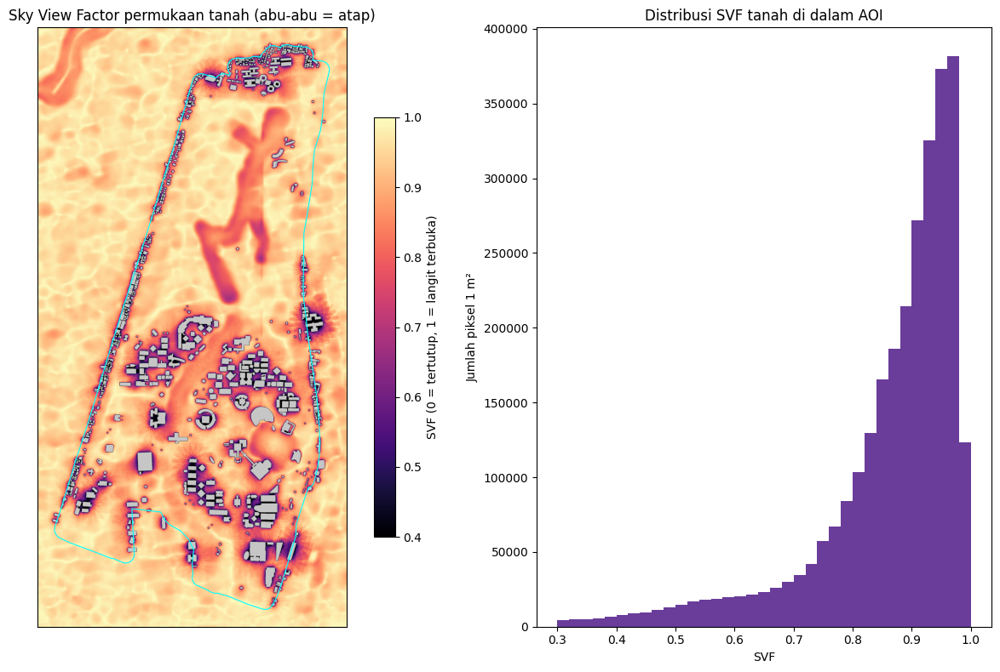

In [11]:
in_aoi = rasterio.features.rasterize([(aoi_buf.geometry.iloc[0], 1)], out_shape=(GH, GW), transform=TR1,
                                     dtype="uint8").astype(bool)
tanah = svf[in_aoi & ~is_bld]
print(f"SVF permukaan tanah kampus: median {np.median(tanah):.2f}; < 0,7 (tertutup): {(tanah < 0.7).mean():.1%}; "
      f"> 0,9 (terbuka): {(tanah > 0.9).mean():.1%}")

prof = dict(driver="GTiff", height=GH, width=GW, count=1, dtype="float32", crs=CRS, transform=TR1, nodata=np.nan,
            compress="deflate", predictor=3, tiled=True)
with rasterio.open(out("svf_1m.tif"), "w", **prof) as dst:  # atap = nodata; dibulatkan 0,01 agar file kecil
    dst.write(np.round(np.where(is_bld, np.nan, svf), 2).astype("float32"), 1)

ext = (gx0, gx0 + GW * RES, gy1 - GH * RES, gy1)
fig, ax = plt.subplots(1, 2, figsize=(13, 8), gridspec_kw=dict(width_ratios=[1.2, 1]))
im = ax[0].imshow(np.where(is_bld, np.nan, svf), cmap="magma", vmin=0.4, vmax=1, extent=ext)
ax[0].imshow(np.where(is_bld, 1, np.nan), cmap="Greys", vmin=0, vmax=3, extent=ext)
aoi_buf.boundary.plot(ax=ax[0], color="cyan", lw=0.8)
ax[0].set(title="Sky View Factor permukaan tanah (abu-abu = atap)", xticks=[], yticks=[])
fig.colorbar(im, ax=ax[0], shrink=0.7, label="SVF (0 = tertutup, 1 = langit terbuka)")
ax[1].hist(tanah, bins=np.arange(0.3, 1.001, 0.02), color="#6a3d9a")
ax[1].set(title="Distribusi SVF tanah di dalam AOI", xlabel="SVF", ylabel="Jumlah piksel 1 m²")
fig.tight_layout()
savefig(fig, "fig27_svf.png")
plt.show()

### SVF dalam 3D

DSM model (diturunkan ke 2 m agar ringan) diwarnai SVF; atap abu-abu. Halaman sempit di antara gedung tinggi dan
lembah danau ber-SVF rendah; lapangan dan jalan lebar mendekati 1. Ingat keterbatasannya: pohon hanya terwakili
gundukan halus DEMNAS 8 m, jadi SVF di bawah tajuk pohon masih terlalu tinggi.

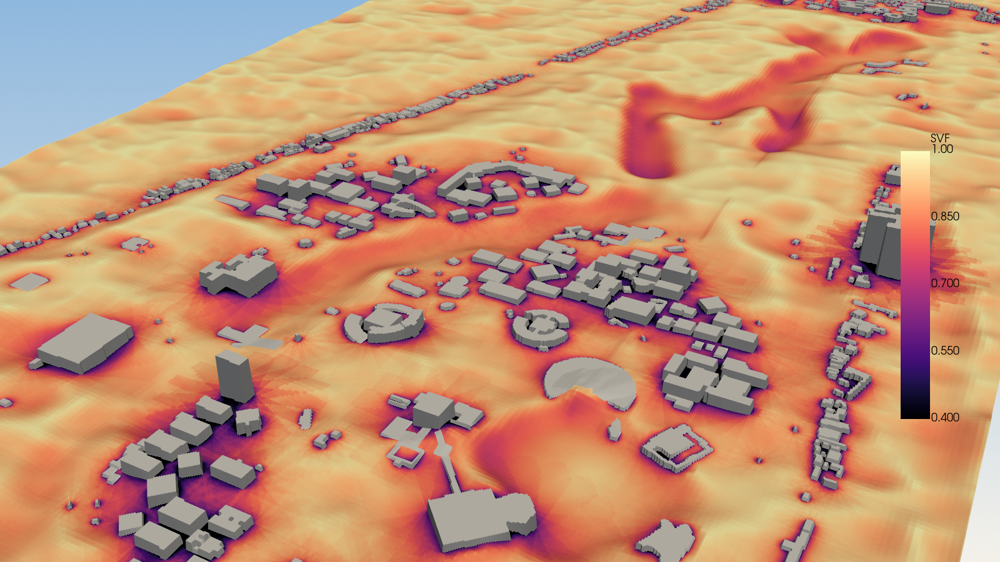

In [12]:
import pyvista as pv

pv.OFF_SCREEN = True
s2 = (slice(None, None, 2), slice(None, None, 2))
Xg, Yg = np.meshgrid(gx0 + (np.arange(GW)[s2[1]] + 0.5) * RES, gy1 - (np.arange(GH)[s2[0]] + 0.5) * RES)
mx, my = Xg.mean(), Yg.mean()
permukaan = pv.StructuredGrid(Xg - mx, Yg - my, dsm[s2] - np.nanmin(dsm))
permukaan.point_data["SVF"] = np.where(is_bld, np.nan, svf)[s2].ravel(order="F")
p = pv.Plotter(window_size=(1600, 900))
p.set_background("#f4f1ea", top="#8fb8de")
p.add_mesh(permukaan, scalars="SVF", cmap="magma", clim=(0.4, 1), nan_color="#c8c8c8",
           scalar_bar_args=dict(title="SVF", vertical=True, position_x=0.9, position_y=0.25, height=0.5))
bx, by = bld.union_all().centroid.coords[0]
p.camera_position = [(bx - mx + 700, by - my - 1300, 900), (bx - mx, by - my, 0), (0, 0, 1)]
p.screenshot(str(fig_path("fig27b_svf_3d.png")))
p.close()
Image.open(fig_path("fig27b_svf_3d.png"))

# 08 — Web-GIS (pengganti ArcGIS Online / .slpk)

1. `TerrainLayer`: permukaan 3D dari tile elevasi AWS Terrain (terrarium) dengan tekstur citra Esri World Imagery,
   di-stream langsung dari server tile (tanpa API key, tanpa menyebar data mentah).
2. `PolygonLayer` gedung `extruded=True`, `get_elevation=Bld_Height`, warna per kategori, tooltip atribut
   (pengganti popup identify). pydeck tidak membawa `TerrainExtension`, jadi tiap poligon diberi koordinat z =
   tinggi terrain web di bawahnya (`terrarium_z`, sampel dari tile yang sama) agar gedung tepat berdiri di tanah.
3. Danau: poligon datar (median terrain di tepinya + 1 m), digambar selalu di atas terrain (`depthCompare`).
4. Opsional `ScenegraphLayer` memuat `ui_lod2.glb` (sudah membawa terrain sendiri, jadi `TerrainLayer` dimatikan).
5. `deck.to_html` → `output/ui3d_web.html`, satu file yang bisa dibuka di browser atau dihosting statis.

Terrain web (SRTM ~30 m) lebih kasar dari DEMNAS, dan tile terrarium hanya sampai zoom 15, sehingga tekstur citra\nikut zoom 15 (~4,8 m/piksel). Versi tajam (citra 0,3 m) ada di `ui_lod2.glb` (bagian 07/11). Peta tampil langsung di bawah sel.
File `output/ui3d_web.html` bisa diunduh dari Drive dan dibuka di browser. Bila LOD2 diaktifkan, `.glb` hanya
terbaca lewat hosting web (mis. GitHub Pages), karena browser memblokir `.glb` dari `file://`.

In [1]:
import json

import geopandas as gpd
import pandas as pd
import pydeck as pdk

from ui3d_common import CATEGORY_COLORS, out, terrain_layer, web_credit, web_ground, web_rings

ADD_LOD2 = False  # True = ganti terrain + gedung PolygonLayer dengan ScenegraphLayer ui_lod2.glb

gdb = out("ui3d.gpkg")
bld = gpd.read_file(gdb, layer="buildings").to_crs(4326).explode(index_parts=False)
water = gpd.read_file(gdb, layer="water").to_crs(4326).explode(index_parts=False)
water = water[water.geom_type == "Polygon"]

# Dasar gedung = titik terendah terrain di bawah footprint, agar tidak melayang di lereng.
b = pd.DataFrame(bld.drop(columns="geometry"))
b["z0"] = web_ground(bld.geometry, 0)
b["polygon"] = [web_rings(g, z) for g, z in zip(bld.geometry, b.z0)]
b["color"] = b.category.map(CATEGORY_COLORS)
b["name"] = b["name"].fillna("").replace("", "(tanpa nama)")
w = pd.DataFrame(water.drop(columns="geometry"))
w["polygon"] = [web_rings(g, z + 1) for g, z in zip(water.geometry, web_ground(water.geometry, 50))]
print(f"Gedung: {len(b)}, danau: {len(w)}; dasar gedung {b.z0.min():.0f}–{b.z0.max():.0f} m (terrain web)")

Gedung: 995, danau: 19; dasar gedung 54–88 m (terrain web)


In [2]:
layers = [
    # SRTM menyimpan kanopi di tepi danau, jadi muka air datar sering tertutup terrain. depthCompare "always":
    # air selalu digambar di atas terrain (relief Depok landai, tidak ada bukit yang seharusnya menutupinya).
    pdk.Layer("PolygonLayer", w, get_polygon="polygon", get_fill_color=[45, 95, 135, 230], stroked=False,
              parameters={"depthCompare": "always"}),
    pdk.Layer("PolygonLayer", b, id="buildings", get_polygon="polygon", extruded=True, get_elevation="Bld_Height",
              get_fill_color="color", get_line_color=[40, 40, 40], pickable=True, auto_highlight=True),
]

if ADD_LOD2:
    o = json.load(open(out("origin.json")))
    layers = [pdk.Layer("ScenegraphLayer", [{"position": [o["lon"], o["lat"], 0]}], scenegraph="ui_lod2.glb",
                        get_position="position", get_orientation=[0, 0, 90], size_scale=1, _lighting="pbr")]
else:
    layers.insert(0, terrain_layer())

c = bld.union_all().centroid
deck = pdk.Deck(
    layers=layers,
    initial_view_state=pdk.ViewState(longitude=c.x, latitude=c.y, zoom=15.6, pitch=55, bearing=-20),
    map_provider=None,
    description=web_credit(),
    tooltip={"html": "<b>{name}</b><br/>Kategori: {category}<br/>Lantai: {levels} ({N_source})<br/>"
                     "Tinggi: {Bld_Height} m<br/>Elevasi dasar: {base_elev} m<br/>Footprint: {footprint_source}"},
)
html = out("ui3d_web.html")
deck.to_html(str(html), open_browser=False)
print("Ditulis:", html)
deck

Ditulis: /home/luwes-system/Desktop/bahan ajar 2026/ui3d/output/ui3d_web.html


{
  "description": "<style>.deck-json-description-box{z-index:10!important;left:0!important;bottom:0!important;top:auto!important}</style><div style='font:11px sans-serif;background:#fffc;padding:2px 6px'>Citra: Esri World Imagery (pendidikan/non-komersial) \u00b7 Terrain: AWS Terrain Tiles (Mapzen, SRTM)</div>",
  "initialViewState": {
    "bearing": -20,
    "latitude": -6.3632481623242345,
    "longitude": 106.82740489533633,
    "pitch": 55,
    "zoom": 15.6
  },
  "layers": [
    {
      "@@type": "TerrainLayer",
      "elevationData": "https://s3.amazonaws.com/elevation-tiles-prod/terrarium/{z}/{x}/{y}.png",
      "elevationDecoder": {
        "bScaler": 0.00390625,
        "gScaler": 1,
        "offset": -32768,
        "rScaler": 256
      },
      "id": "terrain",
      "maxZoom": 15,
      "meshMaxError": 1,
      "texture": "https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}"
    },
    {
      "@@type": "PolygonLayer",
      "data": [
        {
          "id": 28994172,
          "name": "Danau Kenanga",
          "natural": "water",
          "polygon": [
            [
              [
                106.8294416,
                -6.365912199999994,
                75.60546875
              ],
              [
                106.8293086,
                -6.366036700000004,
                75.60546875
              ],
              [
                106.8292093,
                -6.366143400000005,
                75.60546875
              ],
              [
                106.829133,
                -6.366272699999993,
                75.60546875
              ],
              [
                106.8290825,
                -6.366399499999999,
                75.60546875
              ],
              [
                106.8290544,
                -6.3665991999999925,
                75.60546875
              ],
              [
                106.8290323,
                -6.366955499999996,
                75.60546875
              ],
              [
                106.8292576,
                -6.367070999999999,
                75.60546875
              ],
              [
                106.8295231,
                -6.367222999999992,
                75.60546875
              ],
              [
                106.8298075,
                -6.367358899999998,
                75.60546875
              ],
              [
                106.8300532,
                -6.367497499999999,
                75.60546875
              ],
              [
                106.8301548,
                -6.367568799999998,
                75.60546875
              ],
              [
                106.8302856,
                -6.367746100000009,
                75.60546875
              ],
              [
                106.8304807,
                -6.367949399999996,
                75.60546875
              ],
              [
                106.8305665,
                -6.367938699999993,
                75.60546875
              ],
              [
                106.8306631,
                -6.367913400000004,
                75.60546875
              ],
              [
                106.83078110000001,
                -6.3678894,
                75.60546875
              ],
              [
                106.8308642,
                -6.367846700000007,
                75.60546875
              ],
              [
                106.8309554,
                -6.367734800000005,
                75.60546875
              ],
              [
                106.8311017,
                -6.367412100000006,
                75.60546875
              ],
              [
                106.8314244,
                -6.366689600000003,
                75.60546875
              ],
              [
                106.8315281,
                -6.366412599999995,
                75.60546875
              ],
              [
                106.8312418,
                -6.366285699999999,
      

# 09 — Simulasi genangan (pengganti ModelBuilder)

| ModelBuilder (paper) | Python |
| --- | --- |
| Topo to Raster | DEM 8 m dari bagian 02 |
| Fill | `skimage.morphology.reconstruction` |
| Int | `np.floor(dem)` |
| Extract by Attributes | `mask = dem_int <= level` |
| Raster to Polygon | `rasterio.features.shapes` → `geopandas` |
| CGA `touches(all, "water14")` | `geopandas.sjoin(buildings, flood, predicate="intersects")` |

Perbaikan atas paper:
- Hanya sel yang terhubung ke sumber air (danau UI dari OSM) yang tergenang (`scipy.ndimage.label`).
  Versi paper (ambang saja, "naive") tetap dihitung sebagai pembanding.
- DEM bersifat DSM: piksel bangunan dimasking lalu diinterpolasi agar mendekati DTM.

Ini skenario visual berbasis ambang, bukan prediksi banjir hidrologis.

Visual 3D:
- `flood_3d.html` (pydeck): genangan dan gedung di atas terrain web bertekstur citra satelit, sama dengan bagian 08.
- `flood_rise.gif` (PyVista): muka air naik level demi level di atas DTM bertekstur citra; gedung berubah
  kuning → merah saat terdampak. Teknik animasi sama dengan bagian 11.

**Output**: `output/flood_levels.gpkg`, `output/flood_impact.csv`, `output/flood_3d.html`, `output/flood_rise.gif`,
grafik dan peta.

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pydeck as pdk
import rasterio
import shapely
from matplotlib.patches import Patch
from rasterio.features import rasterize, shapes
from scipy import ndimage
from shapely.geometry import shape
from skimage.morphology import reconstruction

from ui3d_common import (CFG, CRS, aoi, dsm_to_dtm, fig_path, out, raw, savefig, terrain_layer, web_credit,
                         web_ground, web_rings)

Fc = CFG["flood"]
gdb = out("ui3d.gpkg")
bld = gpd.read_file(gdb, layer="buildings")
water = gpd.read_file(gdb, layer="water")
aoi_buf = aoi("aoi_buf50")

## Topo to Raster: DEM 8 m dipotong ke AOI + 200 m

In [2]:
with rasterio.open(out("dem_ui_8m.tif")) as s:
    win = rasterio.windows.from_bounds(*aoi_buf.buffer(200).total_bounds, s.transform).round_offsets().round_lengths()
    dem = s.read(1, window=win)
    tr = s.window_transform(win)
shape_ = dem.shape
print("DEM", shape_, f"{np.nanmin(dem):.1f}–{np.nanmax(dem):.1f} m")

DEM (461, 250) 40.1–93.0 m


## DSM → mendekati DTM: masking bangunan + interpolasi

In [3]:
dtm, bmask = dsm_to_dtm(dem, tr, bld, Fc["building_mask_buffer_m"])
print(f"Piksel bangunan diinterpolasi: {bmask.mean():.1%}")

Piksel bangunan diinterpolasi: 11.7%


## Fill → Int

In [4]:
seed = dtm.copy()
seed[1:-1, 1:-1] = dtm.max()
filled = reconstruction(seed, dtm, method="erosion")
dem_int = np.floor(filled)

inside = rasterize([(aoi_buf.geometry.iloc[0], 1)], out_shape=shape_, transform=tr, dtype="uint8").astype(bool)
lo, hi = np.percentile(filled[inside], Fc["level_percentiles"])
levels = np.arange(np.floor(lo), np.ceil(hi) + Fc["level_step_m"], Fc["level_step_m"])
print("Level muka air (m):", levels)

src_water = rasterize([(g, 1) for g in water.geometry], out_shape=shape_, transform=tr, dtype="uint8",
                      all_touched=True).astype(bool)
print("Piksel sumber air (danau/sungai OSM):", int(src_water.sum()))

Level muka air (m): [54. 55. 56. 57. 58. 59. 60. 61. 62. 63. 64. 65.]
Piksel sumber air (danau/sungai OSM): 4576


## Extract by Attributes → konektivitas → Raster to Polygon → bangunan terdampak

In [5]:
def polygonize(mask, level, method):
    geoms = [shape(g) for g, _ in shapes(mask.astype(np.uint8), mask=mask, transform=tr)]
    return gpd.GeoDataFrame({"level_m": [level] * len(geoms), "method": method}, geometry=geoms, crs=CRS)


def affected(flood):
    if flood.empty:
        return set()
    j = gpd.sjoin(bld[["geometry"]], flood[["geometry"]], predicate="intersects")
    return set(j.index)


polys, impact, hit, masks = [], [], {}, {}
for lv in levels:
    naive = (dem_int <= lv) & inside
    lab, _ = ndimage.label(dem_int <= lv)
    ids = np.unique(lab[src_water & (lab > 0)])
    conn = np.isin(lab, ids) & inside if len(ids) else np.zeros_like(naive)
    fn, fc = polygonize(naive, lv, "naive"), polygonize(conn, lv, "connected")
    polys += [fn, fc]
    hit[lv] = affected(fc)
    masks[lv] = conn
    impact.append(dict(level_m=lv, gedung_naive=len(affected(fn)), gedung_terhubung=len(hit[lv]),
                       luas_naive_ha=naive.sum() * abs(tr.a * tr.e) / 1e4,
                       luas_terhubung_ha=conn.sum() * abs(tr.a * tr.e) / 1e4))

flood = pd.concat(polys, ignore_index=True)
flood = gpd.GeoDataFrame(flood, geometry="geometry", crs=CRS)
out("flood_levels.gpkg").unlink(missing_ok=True)
for m in ("connected", "naive"):
    flood[flood.method == m].to_file(out("flood_levels.gpkg"), layer=m)
impact = pd.DataFrame(impact).round(2)
impact.to_csv(out("flood_impact.csv"), index=False)
impact

,level_m,gedung_naive,gedung_terhubung,luas_naive_ha,luas_terhubung_ha
0,54.0,8,8,18.44,18.41
1,55.0,10,10,20.66,20.66
2,56.0,15,15,22.46,22.46
3,57.0,21,21,24.27,24.14
4,58.0,38,35,26.35,26.30
5,59.0,87,87,29.99,29.99
6,60.0,188,188,36.99,36.99
7,61.0,306,306,46.68,46.68
8,62.0,353,353,53.79,53.79
9,63.0,393,393,61.21,61.21


## Gedung terdampak per level (setara Fig. 23)

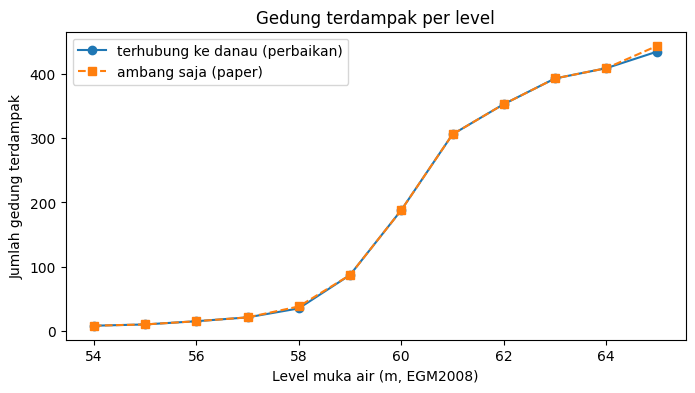

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(impact.level_m, impact.gedung_terhubung, "o-", label="terhubung ke danau (perbaikan)")
ax.plot(impact.level_m, impact.gedung_naive, "s--", label="ambang saja (paper)")
ax.set(xlabel="Level muka air (m, EGM2008)", ylabel="Jumlah gedung terdampak", title="Gedung terdampak per level")
ax.legend()
savefig(fig, "fig23_gedung_terdampak.png")
plt.show()

## Peta merah/kuning (setara Fig. 24): merah = terdampak, kuning = aman

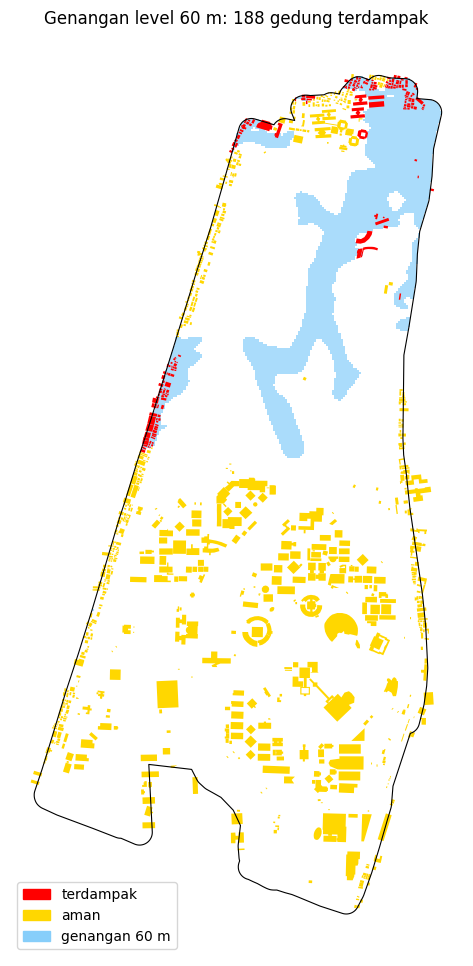

In [7]:
LV = Fc["map_level"] if Fc["map_level"] is not None else float(levels[len(levels) // 2])
LV = float(levels[np.argmin(np.abs(levels - LV))])
is_hit = bld.index.isin(hit[LV])
fl = flood[(flood.method == "connected") & (flood.level_m == LV)]

fig, ax = plt.subplots(figsize=(8, 12))
aoi_buf.boundary.plot(ax=ax, color="k", lw=0.8)
fl.plot(ax=ax, color="lightskyblue", alpha=0.7)
bld[~is_hit].plot(ax=ax, color="gold")
bld[is_hit].plot(ax=ax, color="red")
ax.legend(handles=[Patch(color="red", label="terdampak"), Patch(color="gold", label="aman"),
                   Patch(color="lightskyblue", label=f"genangan {LV:.0f} m")], loc="lower left")
ax.set_title(f"Genangan level {LV:.0f} m: {is_hit.sum()} gedung terdampak")
ax.set_axis_off()
savefig(fig, "fig24_peta_genangan.png")
plt.show()

## Versi 3D di pydeck

In [8]:
b4 = bld.to_crs(4326).explode(index_parts=False)
hit_ids = set(hit[LV])
z0 = web_ground(b4.geometry, 0)  # dasar gedung di terrain web (lihat bagian 08)
df = pd.DataFrame({"name": b4["name"].fillna("").values, "Bld_Height": b4.Bld_Height.values,
                   "status": ["terdampak" if i in hit_ids else "aman" for i in b4.index],
                   "polygon": [web_rings(g, z) for g, z in zip(b4.geometry, z0)]})
df["color"] = df.status.map({"terdampak": [220, 30, 30], "aman": [240, 200, 40]})

# Level dihitung di DEMNAS (EGM2008); terrain web (SRTM) beda datum/bias. Geser level dengan selisih median
# dasar gedung web − base_elev DEMNAS agar muka air menenggelamkan dasar gedung yang memang terdampak.
dz_web = float(np.median(np.array(z0) - b4.base_elev.values))
f4 = fl.to_crs(4326).explode(index_parts=False)
fdf = pd.DataFrame({"polygon": [web_rings(g, LV + dz_web + 0.5) for g in f4.geometry]})
print(f"Selisih terrain web − DEMNAS: {dz_web:+.1f} m")
c = b4.union_all().centroid
deck = pdk.Deck(
    layers=[terrain_layer(),
            # air selalu digambar di atas terrain (depthCompare); bagian gedung di bawah muka air lalu tertutup air
            pdk.Layer("PolygonLayer", fdf, get_polygon="polygon", get_fill_color=[45, 95, 135, 210],
                      stroked=False, parameters={"depthCompare": "always"}),
            pdk.Layer("PolygonLayer", df, get_polygon="polygon", extruded=True, get_elevation="Bld_Height",
                      get_fill_color="color", pickable=True)],
    initial_view_state=pdk.ViewState(longitude=c.x, latitude=c.y, zoom=15.6, pitch=55, bearing=-20),
    map_provider=None,
    description=web_credit(f"Genangan level {LV:.0f} m · "),
    tooltip={"text": "{name}\n{status}\nTinggi {Bld_Height} m"},
)
deck.to_html(str(out("flood_3d.html")), open_browser=False)
deck

Selisih terrain web − DEMNAS: +3.6 m


{
  "description": "<style>.deck-json-description-box{z-index:10!important;left:0!important;bottom:0!important;top:auto!important}</style><div style='font:11px sans-serif;background:#fffc;padding:2px 6px'>Genangan level 60 m \u00b7 Citra: Esri World Imagery (pendidikan/non-komersial) \u00b7 Terrain: AWS Terrain Tiles (Mapzen, SRTM)</div>",
  "initialViewState": {
    "bearing": -20,
    "latitude": -6.3632481623242345,
    "longitude": 106.82740489533633,
    "pitch": 55,
    "zoom": 15.6
  },
  "layers": [
    {
      "@@type": "TerrainLayer",
      "elevationData": "https://s3.amazonaws.com/elevation-tiles-prod/terrarium/{z}/{x}/{y}.png",
      "elevationDecoder": {
        "bScaler": 0.00390625,
        "gScaler": 1,
        "offset": -32768,
        "rScaler": 256
      },
      "id": "terrain",
      "maxZoom": 15,
      "meshMaxError": 1,
      "texture": "https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}"
    },
    {
      "@@type": "PolygonLayer",
      "data": [
        {
          "polygon": [
            [
              [
                106.82830667055539,
                -6.346351218857347,
                64.0575
              ],
              [
                106.82830692565754,
                -6.346423551402241,
                64.0575
              ],
              [
                106.82809003386767,
                -6.346424317041331,
                64.0575
              ],
              [
                106.82809028894256,
                -6.346496649594808,
                64.0575
              ],
              [
                106.82830718076268,
                -6.346495883946923,
                64.0575
              ],
              [
                106.82830743587077,
                -6.346568216491392,
                64.0575
              ],
              [
                106.82852432769438,
                -6.346567450743998,
                64.0575
              ],
              [
                106.82852381742072,
                -6.34642278567244,
                64.0575
              ],
              [
                106.82859611466918,
                -6.346422530409013,
                64.0575
              ],
              [
                106.82859585952673,
                -6.346350197875847,
                64.0575
              ],
              [
                106.82830667055539,
                -6.346351218857347,
                64.0575
              ]
            ]
          ]
        },
        {
          "polygon": [
            [
              [
                106.82628540446397,
                -6.347226352721826,
                64.0575
              ],
              [
                106.82628565931964,
                -6.347298685346228,
                64.0575
              ],
              [
                106.8262133618554,
                -6.347298940322269,
                64.0575
              ],
              [
                106.82621361670392,
                -6.347371272949388,
                64.0575
              ],
              [
                106.82614131922664,
                -6.347371527918276,
                64.0575
              ],
              [
                106.82614182891247,
                -6.347516193177735,
                64.0575
              ],
              [
                106.82606953141206,
                -6.3475164481424,
                64.0575
              ],
              [
                106.82607029593278,
                -6.347733446038785,
                64.0575
              ],
              [
                106.8259979983992,
                -6.347733701002154,
                64.0575
              ],
              [
                106.82599876291636,
                -6.34795069890542,
                64.0575
              ],
              [
                106.82592646534957,
                -6.347950953867492,
                64.0575
              ],
       

## Animasi genangan naik (PyVista)

`FPL` frame per level, kamera berputar pelan. Permukaan tanah = `dtm` (bangunan sudah diinterpolasi) bertekstur
citra konteks z17; gedung = blok LOD1 setinggi `Bld_Height`, kuning (aman) atau merah (terdampak pada level itu).
Muka air = bidang datar `level + 0,5 m` (tengah kelas Int) di atas sel genangan terhubung yang diperlebar 2 sel;
garis pantai terbentuk dari perpotongan bidang itu dengan DTM, jadi tidak bergerigi mengikuti piksel 8 m.

In [9]:
import json

import pyvista as pv
import trimesh
from rasterio.enums import Resampling
from rasterio.vrt import WarpedVRT

pv.OFF_SCREEN = True
FPL = 4  # frame per level
ORIG = json.load(open(out("origin.json")))
OX, OY, ZR = ORIG["x"], ORIG["y"], ORIG["z_ref"]

ny, nx = dtm.shape
xs = tr.c + (np.arange(nx) + 0.5) * tr.a
ys = tr.f + (np.arange(ny) + 0.5) * tr.e
X, Y = np.meshgrid(xs - OX, ys - OY)


def grid_poly(Z, keep):
    """Grid (ny, nx) → PolyData segitiga, hanya sel `keep` (ny-1, nx-1)."""
    idx = np.arange(Z.size).reshape(Z.shape)
    a, b, c_, d = (q[keep] for q in (idx[:-1, :-1], idx[:-1, 1:], idx[1:, 1:], idx[1:, :-1]))
    tri = np.vstack([np.column_stack([a, d, c_]), np.column_stack([a, c_, b])])
    faces = np.column_stack([np.full(len(tri), 3), tri]).ravel()
    return pv.PolyData(np.column_stack([X.ravel(), Y.ravel(), Z.ravel()]), faces)


ground = grid_poly(dtm - ZR, np.ones((ny - 1, nx - 1), bool))
ground.active_texture_coordinates = np.column_stack([(X.ravel() - X.min()) / np.ptp(X),
                                                     (Y.ravel() - Y.min()) / np.ptp(Y)]).astype("float32")
with rasterio.open(raw("imagery_context")) as s, WarpedVRT(s, crs=CRS, resampling=Resampling.bilinear) as v:
    w = rasterio.windows.from_bounds(xs[0], ys[-1], xs[-1], ys[0], v.transform)
    img = v.read((1, 2, 3), window=w, out_shape=(3, round(w.height), round(w.width))).transpose(1, 2, 0)

# Gedung LOD1; `owner` = indeks gedung tiap sel, untuk mewarnai ulang per level.
blocks, owner = [], []
for i, r in bld.iterrows():
    for g in getattr(r.geometry, "geoms", [r.geometry]):
        m = trimesh.creation.extrude_polygon(shapely.affinity.translate(g, -OX, -OY), r.Bld_Height)
        m.apply_translation([0, 0, r.base_elev - ZR])
        blocks.append(m)
        owner += [i] * len(m.faces)
blocks = pv.wrap(trimesh.util.concatenate(blocks))
owner = np.array(owner)
print(f"Grid {ny}×{nx}, gedung {len(bld)} ({blocks.n_cells:,} sel), level {levels[0]:.0f}–{levels[-1]:.0f} m")

Grid 461×250, gedung 995 (17,304 sel), level 54–65 m


In [10]:
AMAN, KENA = np.array([240, 200, 40]), np.array([220, 30, 30])
# Kamera menatap pusat genangan level tertinggi (bukan pusat kampus): di situlah air naik.
cy, cx = np.median(np.argwhere(masks[levels[-1]]), axis=0)
cx, cy = xs[int(cx)] - OX, ys[int(cy)] - OY
FOCUS, R, Z = (cx, cy, 0), 1500, 1100

p = pv.Plotter(window_size=(800, 450))
p.set_background("#f4f1ea", top="#8fb8de")
p.add_mesh(ground, texture=pv.Texture(img))
blocks.cell_data["rgb"] = np.tile(AMAN, (blocks.n_cells, 1)).astype(np.uint8)
p.add_mesh(blocks, scalars="rgb", rgb=True)
p.open_gif(str(out("flood_rise.gif")), fps=4, subrectangles=True)
angles = np.radians(np.linspace(-40, 40, len(levels) * FPL))
for k, lv in enumerate(np.repeat(levels, FPL)):
    if k % FPL == 0:
        kena = np.isin(owner, list(hit[lv]))
        blocks.cell_data["rgb"][:] = np.where(kena[:, None], KENA, AMAN)
        wet = ndimage.binary_dilation(masks[lv], iterations=2)[:-1, :-1]
        p.add_mesh(grid_poly(np.full_like(dtm, lv + 0.5) - ZR, wet), color=(45, 95, 135), opacity=0.9, name="air")
        p.add_text(f"Muka air {lv:.0f} m  ·  {len(hit[lv])} gedung terdampak", position="upper_left",
                   font_size=11, color="white", shadow=True, name="label")
    a = angles[k]
    p.camera_position = [(cx + R * np.sin(a), cy - R * np.cos(a), Z), FOCUS, (0, 0, 1)]
    p.renderer.ResetCameraClippingRange()
    p.write_frame()
p.screenshot(str(fig_path("fig25_genangan_3d.png")))
p.close()
print("flood_rise.gif", f"{out('flood_rise.gif').stat().st_size / 1e6:.1f} MB")

flood_rise.gif 13.7 MB


# 10 — Indoor mapping (pengganti CGA split lantai/ruang)

1. Pilih satu gedung OSM (nama memuat `indoor.name_contains` di config; kosong = gedung terbesar).
2. Split per lantai: lantai dasar `GFl`, lantai berikutnya `Fl`, total `levels` lantai.
3. Tiap lantai: koridor di sumbu panjang `minimum_rotated_rectangle`, ruang di kedua sisi selebar ±6 m.
4. Atribut `BlockName`, `BlockNo`, `FloorNo`, `RoomNo`, `RoomUse` (**asumsi**; ganti dengan data denah bila ada).
5. Visual 3D dengan tooltip identify (setara Fig. 25) dan contoh query "ruang lab di lantai 2".

**Output**: `output/indoor_<gedung>.gpkg`, `output/indoor_<gedung>.glb`, `output/indoor_<gedung>.html`.

In [1]:
import re

import geopandas as gpd
import numpy as np
import pandas as pd
import pydeck as pdk
import trimesh
from shapely import affinity
from shapely.geometry import box

from ui3d_common import CFG, CRS, out

I, Bc = CFG["indoor"], CFG["building"]
GFl, Fl = Bc["GFl"], Bc["Fl"]
bld = gpd.read_file(out("ui3d.gpkg"), layer="buildings")
bld = bld[bld.geom_type == "Polygon"]

## 1. Pilih gedung

Dekanat FTUI: 808 m², lantai=2, Bld_Height=8.5 m


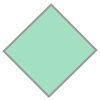

In [2]:
cand = bld[bld["name"].fillna("").str.contains(I["name_contains"], case=False)] if I["name_contains"] else bld.iloc[:0]
pick = (cand if len(cand) else bld).sort_values("area_m2").iloc[-1]
name = pick["name"] or f"gedung_{pick['id']}"
slug = re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_")
print(f"{name}: {pick.area_m2:.0f} m², lantai={pick.levels}, Bld_Height={pick.Bld_Height} m")
pick.geometry

## 2–3. Koridor dan ruang per lantai

Footprint diputar agar sisi panjang `minimum_rotated_rectangle` sejajar sumbu x, dibagi, lalu diputar balik.

In [3]:
fp = pick.geometry
mrr = np.asarray(fp.minimum_rotated_rectangle.exterior.coords)
edges = mrr[1:] - mrr[:-1]
e = edges[np.argmax(np.hypot(edges[:, 0], edges[:, 1]))]
angle = np.degrees(np.arctan2(e[1], e[0]))
c = fp.centroid
rot = affinity.rotate(fp, -angle, origin=c)
x0, y0, x1, y1 = rot.bounds
ym, hw = (y0 + y1) / 2, I["corridor_w_m"] / 2


def back(g):
    return affinity.rotate(g, angle, origin=c)


corridor = back(box(x0, ym - hw, x1, ym + hw).intersection(rot))
rooms = []
for xa in np.arange(x0, x1, I["room_w_m"]):
    xb = min(xa + I["room_w_m"], x1)
    for side, (ya, yb) in (("S", (y0, ym - hw)), ("N", (ym + hw, y1))):
        g = box(xa, ya, xb, yb).intersection(rot)
        if g.area >= I["min_room_m2"] and g.geom_type in ("Polygon", "MultiPolygon"):
            rooms.append((side, back(g)))
print(f"{len(rooms)} ruang per lantai")


def room_use(i, n):
    """Asumsi penggunaan ruang: ujung = toilet/tangga, sisanya bergantian kelas/lab/dosen."""
    if i in (0, n - 1):
        return "Toilet/Tangga"
    return ["Kelas", "Lab", "Ruang Dosen"][i % 3]


recs = []
for floor in range(1, int(pick.levels) + 1):
    z0 = 0.0 if floor == 1 else GFl + Fl * (floor - 2)
    h = GFl if floor == 1 else Fl
    for i, (side, g) in enumerate(rooms):
        recs.append(dict(BlockName=name, BlockNo=str(pick["id"]), FloorNo=floor, RoomNo=f"{floor}{i + 1:02d}",
                         RoomUse=room_use(i, len(rooms)), side=side, z0=z0, height=h, geometry=g))
    recs.append(dict(BlockName=name, BlockNo=str(pick["id"]), FloorNo=floor, RoomNo=f"{floor}K", RoomUse="Koridor",
                     side="-", z0=z0, height=h, geometry=corridor))
indoor = gpd.GeoDataFrame(recs, crs=CRS)
indoor["area_m2"] = indoor.area.round(1)
indoor.to_file(out(f"indoor_{slug}.gpkg"), layer="rooms")
indoor.drop(columns="geometry").head(12)

10 ruang per lantai


,BlockName,BlockNo,FloorNo,RoomNo,RoomUse,side,z0,height,area_m2
0,Dekanat FTUI,151282513,1,101,Toilet/Tangga,S,0.0,4.0,74.5
1,Dekanat FTUI,151282513,1,102,Lab,N,0.0,4.0,75.7
2,Dekanat FTUI,151282513,1,103,Ruang Dosen,S,0.0,4.0,76.3
3,Dekanat FTUI,151282513,1,104,Kelas,N,0.0,4.0,76.2
4,Dekanat FTUI,151282513,1,105,Lab,S,0.0,4.0,76.3
5,Dekanat FTUI,151282513,1,106,Ruang Dosen,N,0.0,4.0,76.2
6,Dekanat FTUI,151282513,1,107,Kelas,S,0.0,4.0,76.3
7,Dekanat FTUI,151282513,1,108,Lab,N,0.0,4.0,76.2
8,Dekanat FTUI,151282513,1,109,Ruang Dosen,S,0.0,4.0,64.8
9,Dekanat FTUI,151282513,1,110,Toilet/Tangga,N,0.0,4.0,63.5


## Contoh query: ruang lab di lantai 2

In [4]:
q = indoor[(indoor.RoomUse == "Lab") & (indoor.FloorNo == 2)]
q[["RoomNo", "RoomUse", "FloorNo", "area_m2"]]

,RoomNo,RoomUse,FloorNo,area_m2
12,202,Lab,2,75.7
15,205,Lab,2,76.3
18,208,Lab,2,76.2


## Model 3D per lantai (glb) dan viewer identify (setara Fig. 25)

In [5]:
USE_COLORS = {"Kelas": [66, 133, 244], "Lab": [219, 68, 55], "Ruang Dosen": [15, 157, 88],
              "Toilet/Tangga": [158, 158, 158], "Koridor": [240, 230, 200]}
scene = trimesh.Scene()
for _, r in indoor.iterrows():
    for g in getattr(r.geometry, "geoms", [r.geometry]):
        if g.geom_type != "Polygon" or g.is_empty:
            continue
        m = trimesh.creation.extrude_polygon(affinity.translate(g, -c.x, -c.y), r.height - 0.15)
        m.apply_translation([0, 0, r.z0])
        m.visual.face_colors = USE_COLORS[r.RoomUse] + [255]
        scene.add_geometry(m, node_name=f"F{r.FloorNo}_{r.RoomNo}")
scene.apply_transform(trimesh.transformations.rotation_matrix(-np.pi / 2, [1, 0, 0]))
scene.export(out(f"indoor_{slug}.glb"))

i4 = indoor.to_crs(4326).explode(index_parts=False)
i4 = i4[i4.geom_type == "Polygon"]
df = pd.DataFrame(i4.drop(columns="geometry"))
df["polygon"] = [[[p[0], p[1], z] for p in g.exterior.coords] for g, z in zip(i4.geometry, i4.z0)]
df["elev"] = df.height - 0.15
df["color"] = df.RoomUse.map(USE_COLORS)
cc = i4.union_all().centroid
deck = pdk.Deck(
    layers=[pdk.Layer("PolygonLayer", df, get_polygon="polygon", extruded=True, get_elevation="elev",
                      get_fill_color="color", opacity=0.6, pickable=True, auto_highlight=True)],
    initial_view_state=pdk.ViewState(longitude=cc.x, latitude=cc.y, zoom=18.5, pitch=60),
    map_provider="carto", map_style="light",
    tooltip={"html": "<b>{BlockName}</b><br/>Lantai {FloorNo} — Ruang {RoomNo}<br/>{RoomUse} ({area_m2} m²)"},
)
deck.to_html(str(out(f"indoor_{slug}.html")), open_browser=False)
deck

{
  "initialViewState": {
    "latitude": -6.361683583594629,
    "longitude": 106.824030566292,
    "pitch": 60,
    "zoom": 18.5
  },
  "layers": [
    {
      "@@type": "PolygonLayer",
      "autoHighlight": true,
      "data": [
        {
          "BlockName": "Dekanat FTUI",
          "BlockNo": "151282513",
          "FloorNo": 1,
          "RoomNo": "101",
          "RoomUse": "Toilet/Tangga",
          "area_m2": 74.5,
          "color": [
            158,
            158,
            158
          ],
          "elev": 3.85,
          "height": 4.0,
          "polygon": [
            [
              106.82398336019097,
              -6.3617460096104645,
              0.0
            ],
            [
              106.8240640521203,
              -6.361827830367667,
              0.0
            ],
            [
              106.8240266,
              -6.361864799999993,
              0.0
            ],
            [
              106.82394538560023,
              -6.36178349458015,
              0.0
            ],
            [
              106.82398336019097,
              -6.3617460096104645,
              0.0
            ]
          ],
          "side": "S",
          "z0": 0.0
        },
        {
          "BlockName": "Dekanat FTUI",
          "BlockNo": "151282513",
          "FloorNo": 1,
          "RoomNo": "102",
          "RoomUse": "Lab",
          "area_m2": 75.7,
          "color": [
            219,
            68,
            55
          ],
          "elev": 3.85,
          "height": 4.0,
          "polygon": [
            [
              106.82396749166838,
              -6.3617299190920935,
              0.0
            ],
            [
              106.8239294143692,
              -6.361767505444156,
              0.0
            ],
            [
              106.8238482,
              -6.361686200000004,
              0.0
            ],
            [
              106.82388681994011,
              -6.361648118763333,
              0.0
            ],
            [
              106.82396749166838,
              -6.3617299190920935,
              0.0
            ]
          ],
          "side": "N",
          "z0": 0.0
        },
        {
          "BlockName": "Dekanat FTUI",
          "BlockNo": "151282513",
          "FloorNo": 1,
          "RoomNo": "103",
          "RoomUse": "Ruang Dosen",
          "area_m2": 76.3,
          "color": [
            15,
            157,
            88
          ],
          "elev": 3.85,
          "height": 4.0,
          "polygon": [
            [
              106.82398336019097,
              -6.3617460096104645,
              0.0
            ],
            [
              106.82402195975732,
              -6.3617079077163226,
              0.0
            ],
            [
              106.82410265148371,
              -6.361789728265124,
              0.0
            ],
            [
              106.8240640521203,
              -6.361827830367667,
              0.0
            ],
            [
              106.82398336019097,
              -6.3617460096104645,
              0.0
            ]
          ],
          "side": "S",
          "z0": 0.0
        },
        {
          "BlockName": "Dekanat FTUI",
          "BlockNo": "151282513",
          "FloorNo": 1,
          "RoomNo": "104",
          "RoomUse": "Kelas",
          "area_m2": 76.2,
          "color": [
            66,
            133,
            244
          ],
          "elev": 3.85,
          "height": 4.0,
          "polygon": [
            [
              106.82400609123538,
              -6.361691817199124,
              0.0
            ],
            [
              106.82396749166838,
              -6.3617299190920935,
              0.0
            ],
            [
              106.82388681994011,
              -6.361648118763333,
              0.0
            ],
            [
              106.82392543987451,
              -6.361610037525382,
              0.0
            ],

# 11 — Animasi orbit 3D (GIF dan MP4)

Model kampus `output/ui_lod2.glb` (bagian 07) dirender ulang dengan PyVista lalu kamera diputar
360° mengelilingi pusat kampus. Hasilnya bisa langsung dipakai di slide atau media sosial.

1. Muat GLB dengan `trimesh`, ubah sumbu glTF (Y ke atas) ke Z ke atas.
2. Ubah tiap mesh ke `pyvista.PolyData`, bawa tekstur citra (terrain, dinding) dan warna vertex (atap, jalan, air).
3. Lintasan kamera: lingkaran berjari-jari `R` pada ketinggian `Z`, menatap pusat gedung.
4. Tulis frame ke GIF (`open_gif`) dan MP4 (`open_movie`).

PyVista punya `generate_orbital_path` + `orbit_on_path`, tetapi di sini kamera diatur sendiri per frame
agar jari-jari dan ketinggian dalam meter terlihat jelas dan mudah diubah.

**Output**: `output/ui_orbit.gif`, `output/ui_orbit.mp4`, `figures/fig26_orbit_frames.png`.

In [1]:
from pathlib import Path

import numpy as np
import pyvista as pv
import trimesh
from PIL import Image

from ui3d_common import fig_path, out

pv.OFF_SCREEN = True  # render tanpa jendela (juga jalan di server)

GLB = out("ui_lod2.glb")
R, Z = 1100, 600            # jari-jari dan tinggi kamera (m) dari pusat kampus
N_GIF, N_MP4 = 48, 180      # jumlah frame: GIF 4 s @12 fps, MP4 12 s @15 fps
GIF_SIZE, MP4_SIZE = (800, 450), (1280, 720)  # piksel; GIF dibuat kecil agar < 15 MB

## 1–2. GLB → PyVista

glTF memakai sumbu `x` = timur, `y` = atas, `z` = selatan. Matriks `YUP_TO_ZUP` memutar −90° di sumbu x
sehingga `z` = atas dan `y` = utara, sesuai konvensi peta.

In [2]:
YUP_TO_ZUP = np.array([[1, 0, 0, 0], [0, 0, -1, 0], [0, 1, 0, 0], [0, 0, 0, 1]], float)


def to_pv(g):
    """trimesh.Trimesh → (pv.PolyData, argumen add_mesh) dengan tekstur atau warna vertex."""
    g = g.copy()
    g.apply_transform(YUP_TO_ZUP)
    m = pv.wrap(g)
    if g.visual.kind == "texture":
        m.active_texture_coordinates = np.asarray(g.visual.uv, "float32")
        img = np.asarray(g.visual.material.baseColorTexture.convert("RGB"))
        return m, dict(texture=pv.Texture(img))
    if g.visual.kind == "vertex":
        m.point_data["rgb"] = np.asarray(g.visual.vertex_colors)[:, :3]
        return m, dict(scalars="rgb", rgb=True)
    return m, dict(color="lightgray")


meshes = {}
for g in trimesh.load(GLB).dump():
    meshes[g.metadata.get("name", f"mesh{len(meshes)}")] = to_pv(g)
for k, (m, kw) in meshes.items():
    print(f"{k:10s} {m.n_points:>8,} titik  {m.n_cells:>8,} sel  {'tekstur' if 'texture' in kw else 'warna'}")

doors         7,960 titik    11,940 sel  warna
windows     354,192 titik   531,288 sel  warna
roofs         5,315 titik     3,337 sel  warna
walls       252,272 titik   126,136 sel  tekstur
water         3,992 titik     3,956 sel  warna
roads        53,302 titik    46,285 sel  warna
terrain_context  216,468 titik   429,500 sel  tekstur
terrain      82,200 titik   163,180 sel  tekstur


## 3. Lintasan kamera

Pusat orbit = median titik atap, bukan pusat terrain, karena terrain melebar 3 km ke utara–selatan
sedangkan gedung terkumpul di tengah kampus.

In [3]:
fx, fy = np.median(meshes["roofs"][0].points[:, :2], axis=0)
FOCUS = (fx, fy, 60)


def orbit(n):
    a = np.linspace(0, 2 * np.pi, n, endpoint=False)  # mulai dari selatan, berputar berlawanan jarum jam
    return np.c_[fx + R * np.sin(a), fy - R * np.cos(a), np.full(n, Z)]


def make_plotter(size):
    p = pv.Plotter(window_size=size)
    p.set_background("#f4f1ea", top="#8fb8de")  # gradasi langit; tepi terrain tidak lagi berbatasan putih polos
    for m, kw in meshes.values():
        p.add_mesh(m, **kw)
    return p


def render(path, size, open_fn, *args, **kw):
    p = make_plotter(size)
    getattr(p, open_fn)(*args, **kw)
    for pos in path:
        p.camera_position = [tuple(pos), FOCUS, (0, 0, 1)]
        p.renderer.ResetCameraClippingRange()
        p.write_frame()
    p.close()


print(f"Pusat orbit: {FOCUS[0]:.0f}, {FOCUS[1]:.0f} m (lokal); jarak pandang {np.hypot(R, Z - FOCUS[2]):.0f} m")

Pusat orbit: 18, -107 m (lokal); jarak pandang 1225 m


## 4. GIF dan MP4

GIF praktis untuk slide tetapi boros: tiap frame disimpan utuh dengan 256 warna, jadi resolusinya dibuat kecil.
MP4 (H.264 lewat `imageio-ffmpeg`) memampatkan antar-frame, jadi resolusi 720p tetap ringan.
`quality` 0–10 mengatur kompresi MP4: makin tinggi, makin tajam dan makin besar.

In [4]:
render(orbit(N_GIF), GIF_SIZE, "open_gif", out("ui_orbit.gif"), fps=12, subrectangles=True)
render(orbit(N_MP4), MP4_SIZE, "open_movie", out("ui_orbit.mp4"), framerate=15, quality=5)
for f in ("ui_orbit.gif", "ui_orbit.mp4"):
    print(f, f"{Path(out(f)).stat().st_size / 1e6:.1f} MB")

ui_orbit.gif 16.8 MB
ui_orbit.mp4 12.7 MB


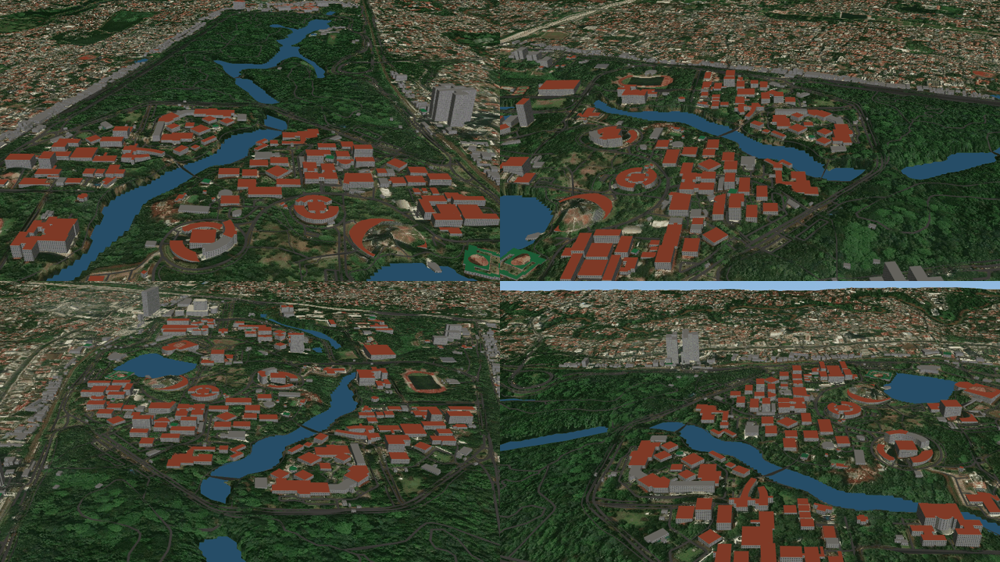

In [5]:
import imageio.v3 as iio

frames = iio.imread(out("ui_orbit.gif"), index=None)
sheet = Image.new("RGB", (1280, 720))
for k, i in enumerate(np.linspace(0, len(frames), 4, endpoint=False).astype(int)):
    sheet.paste(Image.fromarray(frames[i][..., :3]).resize((640, 360)), ((k % 2) * 640, (k // 2) * 360))
sheet.save(fig_path("fig26_orbit_frames.png"))
sheet